# El toyset de MIL-CREDA — figuras y tablas

Esto **no entrena** y **no escribe ningún resultado del flujo**: abre lo que
`Toyset_Generator.ipynb` dejó en disco y dibuja. Las tres familias son las de
`CREDA.toy_experiment.DURAS`, sin tocarlas, y lo único que MIL-CREDA agrega es el
agrupamiento —cada clase partida en bolsas—.

Está al lado del `Toyset_Plot.ipynb` de CREDA y tiene **su misma forma**, y eso
es el punto: un bloque por familia, y cada bloque con **una figura, una tabla y
los tests declarados**, tres bloques iguales. Leer los dos cuadernos uno al lado
del otro y ver qué cambió es lo que se quiere poder hacer, y con dos estructuras
distintas eso no se puede.

**Y esta versión del cuaderno QUITA, no agrega.** Cada bloque llevaba dos
figuras y seis tablas, acumuladas de a una por etapa: una lámina estática
además del cuadro animado, y la tabla mapeada de CREDA, la escalera, las dos
partes del objetivo, la búsqueda y el ancho de banda, cada una por su cuenta. La
lámina se fue —el cuadro animado la reemplaza y lleva además el camino, que una
foto no tiene— y de las cinco tablas quedó una: la escalera, que **es** la
`tabla_dataset` de CREDA, con las columnas de las otras adentro y en la fila del
escalón que las produjo.

**Y en este corte se fueron las conclusiones**, las cuatro: la de la escala, la
de las arquitecturas y las dos de cada bloque de familia. El documento de CREDA
no imprime ninguna —ni en sus tres bloques ni en el resto del archivo— y es la
forma que este cuaderno sigue; la regla general que pide «una conclusión que
salga de una función» no manda sobre la forma concreta que el operador señaló.
Las lecturas que vivían sólo ahí salieron del documento con ellas, nombradas una
por una en la sección de la figura, y siguen en el registro campo por campo. El banner de `toy_tables` arriba de los renderizadores
lleva la contabilidad columna por columna: qué se plegó y qué se dejó caer, con
el motivo.

Lo que viene primero es el artefacto y contra qué se leen sus números, después
los datos y las arquitecturas, después un bloque por familia, y al final el
sopesado —que hoy es una declaración de lo que le falta y no se llena con otra
cosa—.


## Dónde está el repositorio

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


## Lo que el generador dejó

Acá se abre lo que `toy_run.guardar` escribió bajo `MIL-CREDA/Results/Toyset`,
leído de vuelta por `toy_run.cargar` —la mitad que cierra ese par—, y **ningún
número de este cuaderno se recalcula**. Si el artefacto cambia en disco, las
tablas cambian con él; si no está, la celda de abajo corta y no dibuja una tabla
vacía, que es la forma en que una sección sin datos se lee como una sección con
datos malos.

Las tablas las arma `toy_tables`, un módulo que **sólo lee**: no importa `torch`,
no importa `optuna` y no importa `toy_run`, así que no tiene por dónde entrenar,
buscar ni escribir nada. De `toy_run` este cuaderno llama una sola función,
`cargar`, y la llama porque el lector vive al lado del escritor: la vuelta por
disco se prueba cruzando los dos y no verificando cada mitad por su cuenta.

La celda imprime de qué archivos salió todo y cuánto pesa cada uno, porque una
tabla que no dice de dónde vino no se puede volver a medir. Y cruza dos números
que hasta ahora vivían en dos lugares distintos sin que nadie los comparara:
cuántos puntos por dominio dibuja la figura de la próxima sección, y cuántos
midió el barrido. No tienen por qué coincidir y hoy no coinciden.

In [2]:
# El repositorio lo resolvió la celda de arriba --- la de la forja, que viaja
# byte por byte --- y ésta sólo lo usa.
import sys
import textwrap
from pathlib import Path

REPOSITORY = ROOT
sys.path.insert(0, str(REPOSITORY / "src"))

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from MIL_CREDA_Benchmark import figures, toy_bags, toy_run, toy_tables

# El directorio de la figura archivada, al lado del cuaderno y no bajo
# `Results/`: lo que este cuaderno dibuja no es un resultado del flujo --- no
# compara los dominios de `config.DOMAINS` ni escribe bajo
# `config.results_for(...)` --- así que no lleva ninguna de las coordenadas con
# que se nombra una corrida. Se redibuja entero en cada ejecución, de modo que
# no hay dos versiones entre las cuales elegir.
FIGURAS = ROOT / "MIL-CREDA" / "Notebooks" / "toy_figures"

# El cuadro animado de cada familia, escrito y medido por la celda de su
# `## <familia>` y mostrado por la celda de su figura. Dos celdas y no una,
# porque la celda de la figura emite la imagen sola: lo que se midio al
# dibujar lo imprime la celda de arriba, que es donde el `animar(...)` del
# cuaderno de CREDA lo imprime.
ANIMACIONES: dict = {}

ARTEFACTO = toy_run.destination(toy_run.PILOT, REPOSITORY)
if not (ARTEFACTO / "barrido.json").exists():
    raise FileNotFoundError(
        f"no hay artefacto en {ARTEFACTO}: corré `Toyset_Generator.ipynb` "
        "primero. Esto corta a propósito --- una tabla vacía acá se lee igual "
        "que una tabla con números malos.")

REGISTRO = toy_run.cargar(ARTEFACTO)

print("repositorio:      ", REPOSITORY)
print("leído de:         ", ARTEFACTO.relative_to(REPOSITORY))
for _r in sorted(ARTEFACTO.iterdir()):
    print(f"  {_r.name:16s} {_r.stat().st_size:>9,} bytes")
print()
print("revisión del artefacto:", REGISTRO["flags"]["revision"])
print("escala:                ", REGISTRO["scale"]["name"],
      "(ensayo)" if REGISTRO["scale"]["isPilot"] else "(completa)")
print("familias:              ", ", ".join(toy_tables.familias(REGISTRO)))
print("normalizaciones:       ",
      ", ".join(toy_tables.normalizaciones(REGISTRO)),
      "· ausentes:", ", ".join(toy_tables.ausentes(REGISTRO)) or "ninguna")
print("brazos:                ", ", ".join(REGISTRO["flags"]["arms"]))
print("celdas / filas:        ",
      len(REGISTRO["cells"]), "/", len(REGISTRO["rows"]))
print("bolsas por clase:      ", toy_bags.BAGS_PER_CLASS_TOY)
print()
# El cruce que no estaba hecho. La figura de la próxima sección se dibuja con
# el default de `toy_bags` y el barrido se midió con lo que su escala declara;
# son dos sorteos del mismo generador con la misma semilla y distinto `n`, así
# que no son los mismos puntos ni las mismas bolsas. Nada de esto se arregla
# acá --- cambiar el sorteo cambia lo que la sección de datos mide, y eso no es
# una decisión de este trabajo --- pero deja de ser invisible.
PUNTOS_DIBUJADOS = toy_bags.PUNTOS_POR_DOMINIO
PUNTOS_MEDIDOS = REGISTRO["scale"]["points_per_domain"]
print("puntos por dominio que DIBUJA la figura de los datos:", PUNTOS_DIBUJADOS)
print("puntos por dominio que MIDIÓ el barrido:             ", PUNTOS_MEDIDOS)
print("   coinciden:", PUNTOS_DIBUJADOS == PUNTOS_MEDIDOS,
      f"(diferencia {PUNTOS_DIBUJADOS - PUNTOS_MEDIDOS})")
if PUNTOS_DIBUJADOS != PUNTOS_MEDIDOS:
    print("   -> la figura y las lecturas de datos describen un sorteo y las")
    print("      tablas de cada familia se midieron sobre otro: mismo")
    print("      generador y misma semilla, distinto número de puntos, así que")
    print("      distintas bolsas. Leer una contra la otra es cruzar dos")
    print("      sorteos.")
print()
print("lo que esta corrida NO puede contestar, leído de las banderas:")
for _linea in textwrap.wrap(REGISTRO["flags"]["armsNote"], 84):
    print(f"  {_linea}")

/Users/diego/Proyectos/papersmith-ai/implementations/Domain_Adaptation/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


repositorio:       /Users/diego/Proyectos/papersmith-ai/implementations/Domain_Adaptation
leído de:          MIL-CREDA/Results/Toyset/pilot
  banderas.json       28,845 bytes
  barrido.json       157,355 bytes
  lunas.npz          490,453 bytes
  rollo.npz          490,087 bytes
  toroide.npz        490,342 bytes

revisión del artefacto: research-concept-r34.md
escala:                 pilot (ensayo)
familias:               lunas, toroide, rollo
normalizaciones:        ninguna, batchnorm, layernorm · ausentes: ninguna
brazos:                 TGL
celdas / filas:         9 / 9
bolsas por clase:       27

puntos por dominio que DIBUJA la figura de los datos: 1800
puntos por dominio que MIDIÓ el barrido:              2835
   coinciden: False (diferencia -1035)
   -> la figura y las lecturas de datos describen un sorteo y las
      tablas de cada familia se midieron sobre otro: mismo
      generador y misma semilla, distinto número de puntos, así que
      distintas bolsas. Leer una contra l

## Las tres familias, con cada clase en bolsas

La figura es la de CREDA con dos cosas encima. Las posiciones, los tonos por clase y
los marcadores por dominio son los suyos y no se tocan: lo único que MIL-CREDA agrega
es el agrupamiento, y entra por el **casco** —cada bolsa encerrada entera en su propia
envolvente convexa— y por el **rótulo** que dice cuál es. Importa que sea en ese orden
y no al revés. Si el agrupamiento hubiera movido las posiciones, MIL-CREDA se estaría
midiendo sobre datos distintos de los de CREDA, y la comparación entre los dos —que es
para lo que este cuaderno está al lado del otro— dejaría de decir nada.

El nombre de una bolsa es `B` + dominio + clase + bolsa, y las dos últimas se cuentan
**desde uno**: `Bs11` es la bolsa 1 de la clase 1 en la fuente, `Bt34` es la bolsa 4 de
la clase 3 en el blanco. Los arreglos las cuentan desde cero —las clases son 0, 1 y 2—,
así que la leyenda de clases muestra las dos numeraciones una al lado de la otra, que
es el único lugar donde se ven juntas.

**Y al corte de hoy el nombre dejó de tener una sola lectura.** El índice de bolsa
llega a dos dígitos, así que la bolsa 12 de la clase 1 se llama `Bs112` —que sólo se
puede leer sabiendo de antemano que el índice de clase es de un dígito, lo cual es
cierto para las tres clases de CREDA y no es una propiedad del nombre—. El formato **no
se cambió acá**: separar los dos índices es una decisión sobre cómo la figura nombra una
bolsa, y lo que corresponde es informar la ambigüedad.

**El canal que se retiró.** El agrupamiento entraba antes por la luminosidad: el tono de
la clase aclarado banda por banda. Mirada la figura dibujada, no se leía —cuatro tintes
de un mismo color no se ordenan de un vistazo— y encima le sacaba fuerza al tono, que es
el que lleva la clase. El casco dice exactamente qué puntos van juntos sin pedirle nada
al ojo, y el tono vuelve a fuerza plena.

Lo que hay que mirar es si cada casco encierra un **tramo** de la variedad y no un puñado
de puntos repartidos por ella. Si se viera moteado, el escalar que ordena las bandas no
sería el que el generador usó para cortar las clases y entonces las bandas serían bandas
de otra cosa: un defecto sin síntoma, porque `n` grupos de puntos siguen pareciéndose a
`n` bolsas por mal cortadas que estén. Por eso no se deja a la vista.
`toy_bags.clase_reproducida` replica el corte del generador desde el escalar recuperado,
y la tabla de datos de cada familia informa en cuánto coincide.

**Lo primero que hay que leer de la celda de abajo es si el canal del RÓTULO se lee, y
al corte de hoy la respuesta es que no.** Un panel dibuja `3 × n × 2` cascos y otros
tantos nombres —los **dos** dominios, no uno, y ése es el factor que se olvida contando
cascos por clase—, y cuanto más fino el corte, más nombres entran en el mismo panel sin
que la geometría cambie. Ningún número de esa medición está escrito acá: la celda de
abajo la computa panel por panel, informa cuántos **nombres** quedan debajo de otro —no
sólo qué fracción de los pares se cruza, que es la cifra que engaña— y dice en voz alta
cuándo más de la mitad de los nombres de un panel está tapada.

Lo que eso significa para leer esta figura: **el casco sigue diciendo qué puntos van
juntos y el nombre ya no dice cuál es cada grupo.** Es el mismo tipo de falla por la que
la luminosidad se retiró una vez —un canal que el ojo no puede resolver—, en otro canal.
Los nombres se dejaron en el panel a propósito: qué canales lleva la figura es una
decisión del operador, y lo que corresponde acá es que la falla se vea en números
medidos en vez de que alguien la descubra intentando leer un panel.

Los dos arreglos que se probaron se midieron **con un corte más grueso que el de hoy** y
no se volvieron a medir; se dejan fechados como lo que son, y nada de esta corrida los
recomputa. Correr el rótulo hacia afuera del centro de su clase lo sacaba del casco que
nombra —con un corrimiento chico quedaba adentro menos de un tercio de los rótulos de
`lunas` y de `rollo`— sin bajar ni un par encimado, y de ahí en adelante empezaba a
encimar los de `toroide`. Achicar la letra bajaba a la mitad los pares encimados de
`lunas`, a cambio de un nombre que ya casi no se lee. El otro límite, que no se movió, es
que los cascos de clases distintas se superponen y sus colores se mezclan —rojo sobre
verde lee marrón—; también es la geometría, y la alternativa sería un casco opaco, que
taparía justo los puntos que encierra.

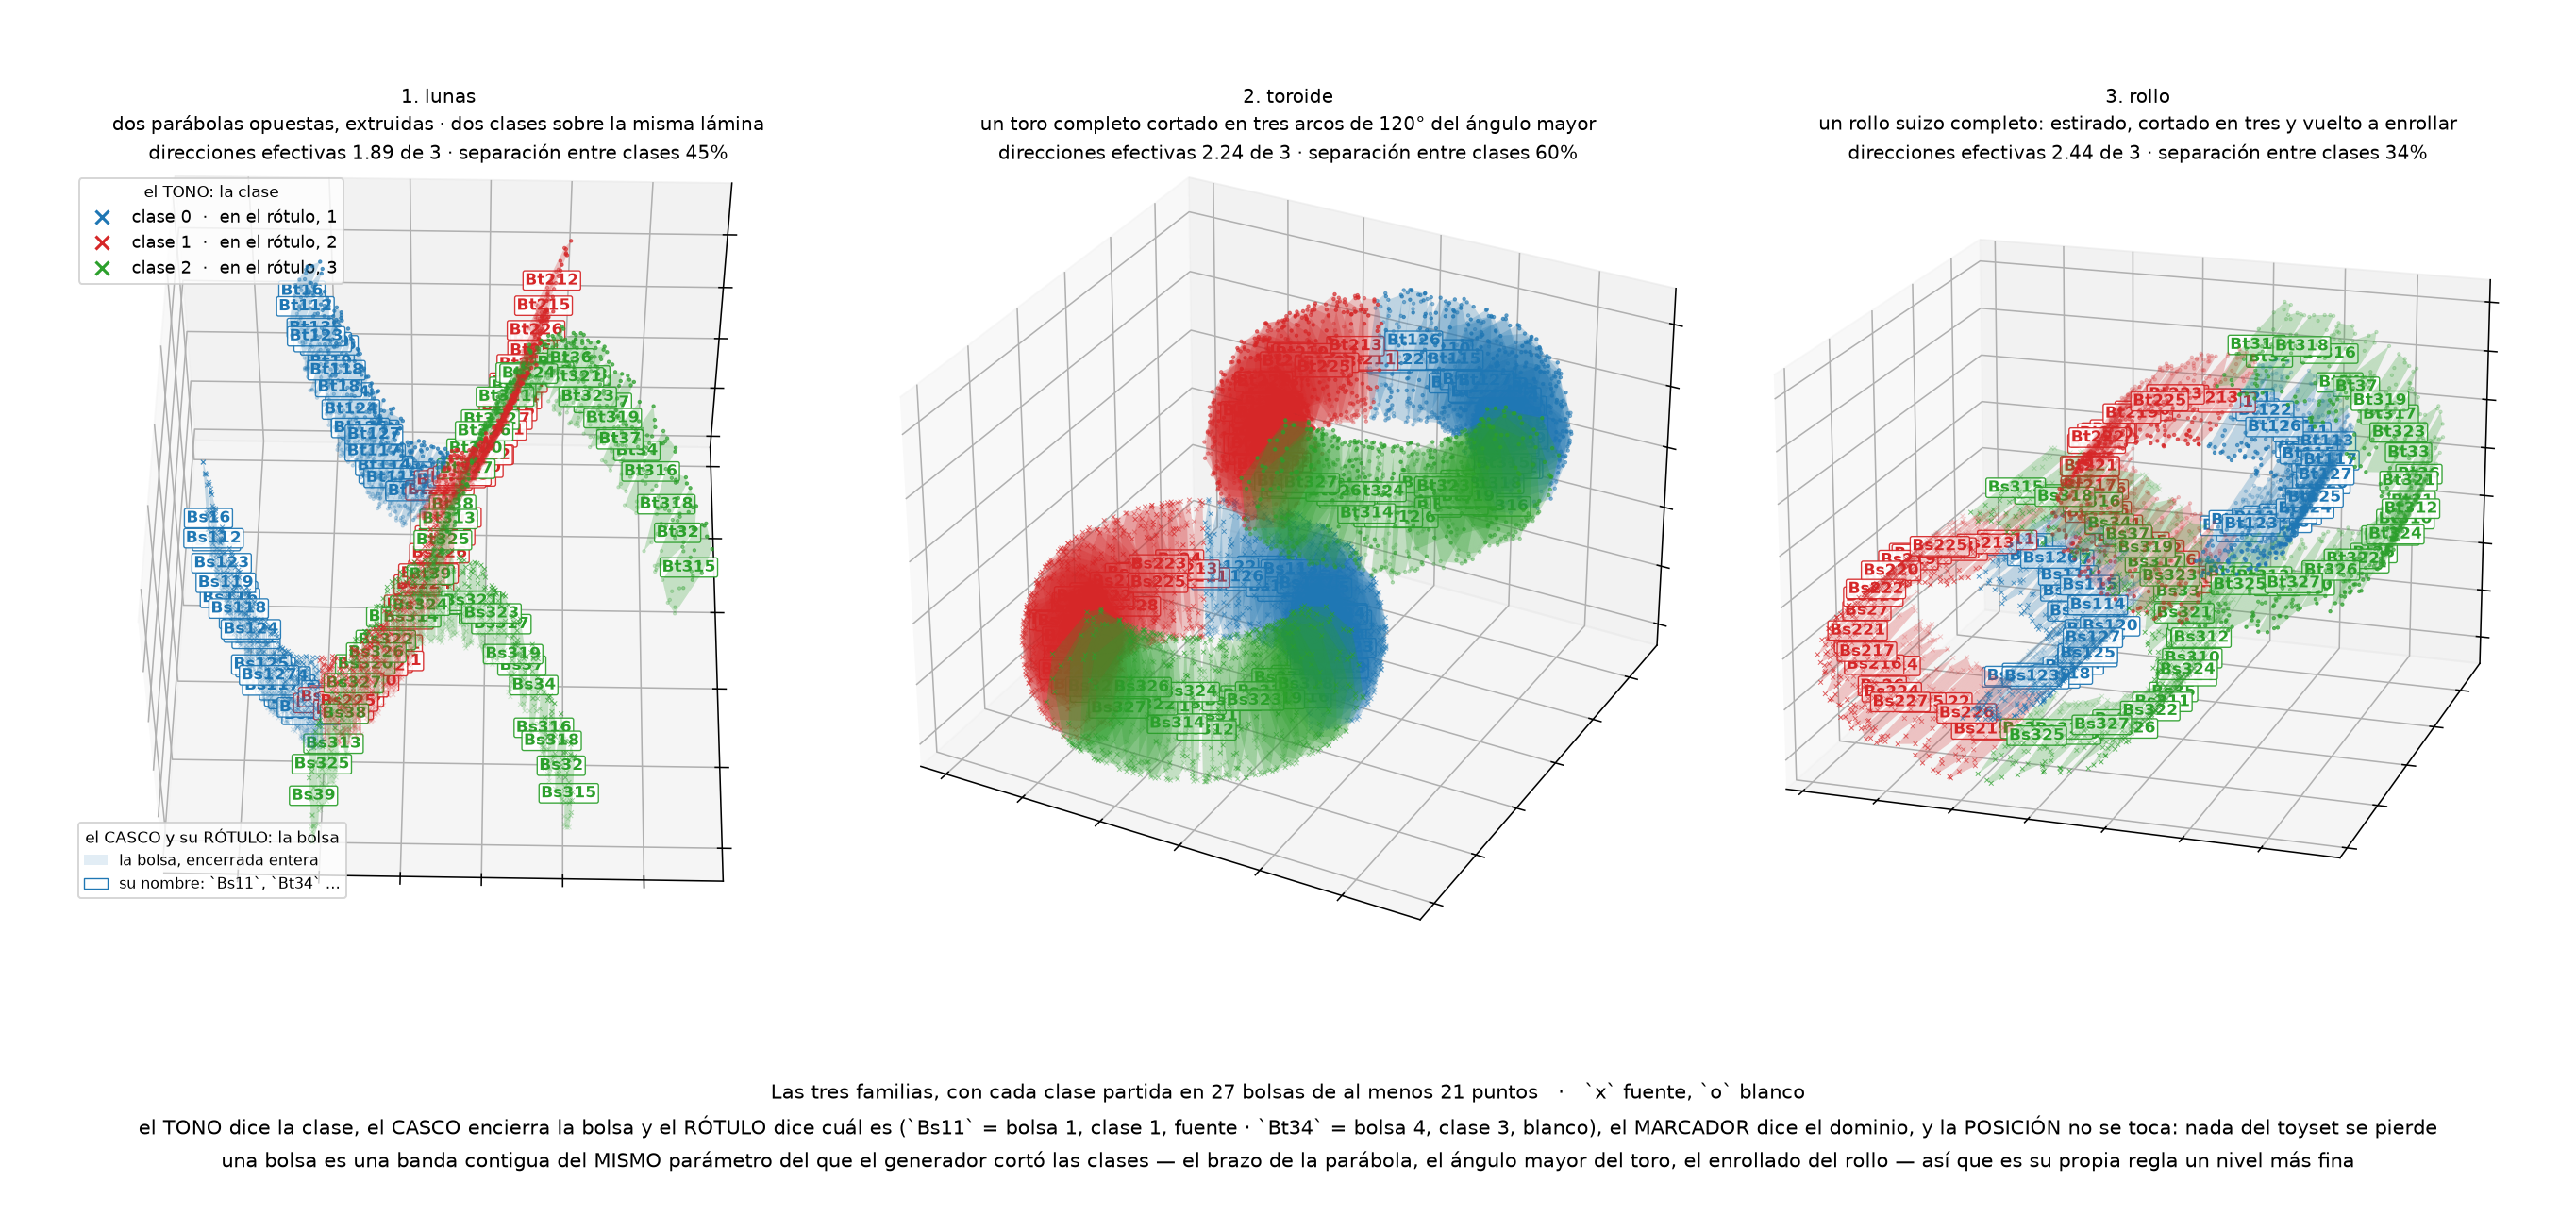

In [3]:
# La figura se archiva en vectorial Y se muestra acá adentro. La miniatura la
# rasteriza `figures.inline`, porque `figures` fija el backend `Agg` y bajo
# `Agg` un `display(fig)` pelado imprime `<Figure size ...>` en lugar de
# dibujar.
#
# La celda emite la imagen y NADA MAS, que es la forma de la celda equivalente
# del cuaderno de CREDA: la suya archiva con `savefig` y muestra, sin imprimir
# una sola linea. Lo que esta celda imprimia --- la ruta del archivo, si los
# paneles comparten ejes, y el encimado de los rotulos panel por panel --- lo
# sigue MIDIENDO la llamada de abajo, que es donde se mide, y lo siguen
# cruzando sus tests en `tests/test_toy_bags.py`. Lo que se retiro es su
# reporte en este documento, no la medicion.
#
# El nombre de esa llamada NO se repite en este comentario a proposito:
# `test_every_family_block_carries_its_figure_and_not_the_dataset_again`
# cuenta sus apariciones en la fuente de las celdas para atajar un segundo
# dibujo del dataset, y una mencion en prosa le sube el conteo a dos.
_familias = toy_bags.figura_familias(FIGURAS)
display(figures.inline(_familias.fig))
plt.close(_familias.fig)


## Las tres arquitecturas

**Son tres, las mismas tres que dibuja CREDA**, y el conteo de columnas de la
tabla de abajo **lo imprime el registro**: el día que aparezca un backbone más,
la tabla crece sola y el título de esta sección queda contradicho por la tabla
que tiene debajo. Esa fue exactamente la falla que esta sección existe para no
repetir —antes decía tres sobre una grilla de dos— y lo que cambió no es el
título: es que la tercera arquitectura ahora está.

Las tres son `ninguna` —sin normalización en ninguna capa—, `batchnorm`
—`BatchNorm1d` en las dos posiciones— y `layernorm` —`LayerNorm` en esas mismas
dos posiciones—, y `mlp.MLP_BACKBONES` declara exactamente esos tres backbones.
Las tres comparten los anchos, la activación y, dada la misma semilla, las tres
matrices de pesos bit a bit: ni `BatchNorm1d` ni `LayerNorm` sacan nada del
generador al inicializarse, así que insertar, sacar o cambiar una no corre los
sorteos que reciben las capas lineales. El único eje en el que dos de ellas
difieren es qué capa va en esas dos posiciones.

**Por qué está la tercera, y no es simetría con la figura de al lado.** Es el
**control** que separa «normalizar ayuda» de «reestimar ayuda». BatchNorm hace
dos cosas a la vez: normaliza, y guarda `running_mean`/`running_var`, que es
estado que el dominio nuevo puede **reestimar** sin optimizador y sin una sola
etiqueta del blanco —eso es AdaBN—. LayerNorm normaliza y **no guarda ninguna
estadística corrida**, así que AdaBN no tiene escalón en esa fila: la celda va
con raya y con el motivo medido al lado. Sin esa fila, una fila de BatchNorm que
lee por encima de `ninguna` no se puede atribuir: pudo ganar por normalizar o
pudo ganar porque le reestimaron las estadísticas, y nada más de este cuaderno
las separa. El régimen donde la distinción decide es el que la tabla de cada
familia muestra: donde el escalón de AdaBN llega al del método o lo pasa.

La tabla mide dos de sus filas en vez de afirmarlas: **cuántas capas normalizan**
y **cuántas de ésas puede reestimar AdaBN**, las dos leídas de la corrida celda
por celda. Un backbone puede normalizar y no tener nada reestimable, y sólo el
registro puede decir cuál de los dos casos es una fila. Los parámetros se miden
igual: el código chequea que sean los mismos en las tres familias antes de
imprimir un número, y si alguna vez difieren imprime el rango que encontró en
vez de un número que describe a una sola.

**Una tabla y nada debajo.** Debajo había una conclusión calculada —qué
arquitectura leía por encima de cuál, restado dentro de cada familia— y se
retiró: la celda de CREDA de esta misma sección emite una tabla sola. La
comparación que separa «normalizar ayuda» de «reestimar ayuda» no se fue con
ella: está en las dos filas medidas de la tabla, las que cuentan capas que
normalizan y capas que AdaBN puede reestimar. Lo que sí se fue es el conteo de en
cuántas familias cada arquitectura leía por encima de `ninguna`.


In [4]:
display(Markdown(toy_tables.render_arquitecturas(REGISTRO)))
# El renglon que cierra la celda, como lo cierra la celda equivalente de CREDA
# --- la suya imprime las capas ocultas y los modulos por red, computados de
# los modelos REALES y no escritos a mano. Este sale del REGISTRO por la MISMA
# via con que la tabla de arriba se armo: las columnas son
# `toy_tables.normalizaciones(REGISTRO)`, que es de donde esa tabla saca su
# conteo de columnas, y las capas son las que la corrida MIDIO celda por celda.
#
# Un conjunto por arquitectura y no un promedio, que es la disciplina de
# `_constante` dentro de `render_arquitecturas` y por el mismo motivo: «todas
# las celdas de esta columna miden lo mismo» es una creencia, y una creencia
# impresa como un numero es de las que dejan de ser verdad sin que nadie se
# entere. Si dos celdas de la misma columna discrepan, el renglon dice el rango
# en vez de describir una de ellas.
_declaradas = toy_tables.normalizaciones(REGISTRO)
_capas = {_n: sorted({_c["adabnNormLayers"]
                      for _c in toy_tables.celdas(REGISTRO)
                      if _c["normalization"] == _n})
          for _n in _declaradas}
print(f"arquitecturas medidas: {len(_declaradas)}  ·  "
      "capas que normalizan por arquitectura: ["
      + ", ".join(str(_v[0]) if len(_v) == 1 else f"{min(_v)} a {max(_v)}"
                  for _v in (_capas[_n] for _n in _declaradas))
      + "]")


| qué | ninguna | batchnorm | layernorm |
|---|---|---|---|
| backbone | `mlp-nobn` | `mlp` | `mlp-layernorm` |
| celdas medidas | 3 | 3 | 3 |
| parámetros del brazo | 15,235 | 15,491 | 15,491 |
| parámetros, relativo a «ninguna» | 1.0000 | 1.0168 | 1.0168 |
| capas que normalizan (medido en la corrida) | 0 | 2 | 2 |
| capas que AdaBN puede reestimar (medido en la corrida) | 0 | 2 | 0 |
| estado que la fase 2 reestima | ninguno | `running_mean`, `running_var` | ninguno — y eso es lo que la hace el CONTROL de esta grilla |
| normaliza sobre | nada | el **lote**, por canal | los **features**, dentro de cada muestra |
| por qué está o no está | declarada y corrida | declarada y corrida | declarada y corrida |

arquitecturas medidas: 3  ·  capas que normalizan por arquitectura: [0, 2, 2]


## La figura, una por dataset

De acá en adelante va **un bloque por familia**, y los tres tienen la misma
forma: una figura, una tabla y los tests declarados. Es la forma del cuaderno de
CREDA y se sigue a propósito, para que los dos se puedan leer uno al lado del
otro.

**Una figura por bloque, y es el cuadro animado.** Había dos: una lámina
vectorial estática —un panel por arquitectura, con la fuente congelada, el
blanco antes y el blanco después, y un segmento uniendo las dos posiciones de
cada bolsa— y debajo el cuadro animado. La lámina **se retiró**: el cuadro
animado dibuja las mismas posiciones y lleva además lo que la foto no puede
llevar, que es el camino —entre el antes y el después hay pasos—, así que las
dos juntas eran una medición dibujada dos veces y la que sobra es la que no
tiene los pasos.

**Qué es el cuadro animado.** Es la figura por dataset del cuaderno de CREDA,
con su misma forma: **filas = normalizaciones, cuatro columnas**, y los cuadros
son las **épocas de la fase 2**. Las columnas uno y dos llevan **las mismas
posiciones** y difieren sólo en el color —clase real contra decisión del
cabezal—, así que la diferencia entre los dos paneles se lee como lo que el
cabezal erró y como nada más; las otras dos son las dos pérdidas, la de la fase
1 y la de la fase 2, al lado.

**Qué espacio es, dicho con el número de ecuación correcto.** Es la
representación **euclidiana** de la bolsa, la de la Ec. 19: la combinación
convexa de los embeddings de sus instancias, que es sobre la que opera el
clasificador. No es `Psi(B)`, la de la Ec. 17, que vive en el espacio del kernel
y **no tiene coordenadas que escribir**: de ella sólo existen los productos
internos de la Ec. 18, que es con lo que la alineación trabaja. Las dos son «la
representación de la bolsa» y son objetos distintos; sólo la primera es una
posición. Dibujar la otra sería un kernel-PCA de la matriz de Gram, que es otra
figura y otra decisión.

**Y la figura no se rellena con el dataset dibujado de nuevo.** Los datos crudos
se muestran una sola vez, arriba. Un lector que encontrara dos figuras distintas
en el mismo lugar del mismo árbol leería una como la otra, y que el lugar esté
ocupado no vuelve esa sustitución menos posible: es justo lo que una celda de
figura podría pasar a ser en silencio.

**Los dos sorteos que esta sección cruza, y que no son el mismo.** La figura de
los datos de más arriba dibuja el default de `toy_bags`; **ésta sale de la
corrida**, así que describe el sorteo que la escala declara. Los dos números los
imprime la celda de «lo que el generador dejó», y no coinciden: mismo generador,
misma semilla, distinto número de puntos, así que distintas bolsas.

**Las filas salen del registro y no de esta frase**: `normalizations` dice
cuáles corrieron y `normalizationsAbsent` cuáles no tienen backbone en este
paquete. Las dos lecturas se publican: las imprime la celda que precede a cada
figura y las llevan las tablas de más abajo. **El pie del cuadro ya no las
repite.** El operador resolvió el 2026-10-15 que esta figura lleva el marco de
CREDA —mismos límites, mismas cosas—, y el pie de CREDA es **una** línea: una
lectura sin contraparte en ese marco sale de la figura, en vez de mudarse a un
rincón más silencioso de ella.

**La fuente está quieta y el cuadro lo dice con el número que lo mide.** La fase
2 mueve `theta_t` y nada más —ni el codificador de la fuente ni el cabezal están
en el optimizador—, así que el único término con camino de gradiente es el de la
adaptación y el número del blanco es atribuible a él. Que esté quieta es una
medición: `latentSourceMoved`, que el pie imprime.

**El acercamiento y su complemento se retiraron del cuadro, y las dos columnas
dicen lo que dicen las de CREDA.** La primera columna informaba la distancia
entre centroides y la dispersión del blanco, y la segunda cuántas bolsas había
errado el cabezal: dos lecturas distintas bajo dos paneles que sólo se
diferencian en el color. Las dos columnas de CREDA llevan **una** lectura, la
misma repetida, así que con su marco esa asimetría se fue —y con ella la
implementación que calculaba el acercamiento, que no quedó apuntando a ninguna
parte—. Lo que las dos columnas informan ahora es lo que informa CREDA, con la
unidad de este experimento: el acierto sobre el **blanco** y sobre la
**fuente**, de bolsa y no de punto, medidos sobre las bolsas que el cuadro
dibuja. CREDA lleva ahí un tercer número, su `ruteo`, que acá no tiene
contraparte y no se inventa una: lo que rutea en este término es la clase
decidida de la bolsa, que es de donde ya sale el acierto del blanco, así que una
columna de ruteo imprimiría el mismo número dos veces con dos nombres. Un
colapso del blanco se sigue viendo donde siempre estuvo, en los cuadros: la nube
se contrae.

**La zancada está declarada.** No se guarda un cuadro por paso: se guarda uno
cada `k`, más el paso 0 y el último siempre. El cuaderno del generador imprime
`k`, los cuadros que salieron y lo que la trayectoria cuesta en disco, para esta
corrida y proyectado a la escala completa.

**Una tabla por bloque, y es la `tabla_dataset` de CREDA.** No una versión
mapeada de ella: sus **ocho columnas**, en su orden, y sus **siete filas**. Las
filas son los **escalones de intervención**, de menos a más, que es el orden en
que hay que leerla —la pregunta que contesta cada escalón es qué dejó sobre la
mesa el de abajo—: primero `.predict` una vez por arquitectura, después AdaBN, y
al final MIL-CREDA una vez por arquitectura.

**Los tres escalones, qué mueve cada uno y cómo se leyó.** Se dice acá, una vez
para los tres bloques, porque es la misma explicación para las tres familias y
una explicación impresa una vez por familia es la misma frase tres veces:

- **`.predict` (sin adaptar)** no mueve **nada**. Es el punto de control del
  paso 0 de esta misma corrida, donde `theta_t` es todavía `theta_s` bit a bit,
  leído en `eval()`. No es un brazo y no cuesta un segundo barrido: comparte la
  fase 1 con los dos escalones de arriba bit a bit, que es la razón por la que
  CREDA lo lee ahí en vez de entrenar un piso aparte.
- **AdaBN (sólo buffers, sin optimizador)** mueve **sólo las estadísticas
  corridas de la normalización del blanco**. Es ese mismo punto de control con
  las corridas reestimadas sobre lotes del blanco: sin optimizador, sin
  `backward`, sin un solo paso y sin una sola etiqueta del blanco. Sobre cuánto
  material las reestimó este documento **ya no dice nada**: lo decía la
  conclusión de cada bloque, y las conclusiones se retiraron porque el documento
  de CREDA que este cuaderno sigue no lleva ninguna. El campo sigue en el
  registro (`adabnBatches`) y quien lo necesite lo lee de ahí.
- **MIL-CREDA · HP sintonizados** mueve **el codificador del blanco entero**. Es
  la fase 2 completa bajo los dos términos de la Ec. 39, restaurada en el paso
  que su paro eligió.

**AdaBN es UNA fila, y la arquitectura de esa fila la decide la medición.** No es
un escalón repetido por arquitectura con raya donde no aplica. AdaBN existe donde
el backbone guarda estadísticas corridas que reestimar, y eso lo dice la corrida
celda por celda —cuántas capas encontró que puede reestimar—, nunca el nombre de
la capa. Una arquitectura que no guarda nada **no tiene fila de AdaBN**, que es
la forma de la tabla de CREDA: la suya lleva una sola fila de AdaBN, la de
BatchNorm. La ausencia de la fila **es** la lectura; un número ahí sería el
escalón cero con otro nombre, y una fila con raya diría «AdaBN se midió y salió
vacía», que es otra cosa. Que esa ausencia sea el **control** de la grilla —la
arquitectura que normaliza y no guarda nada— lo dicen las **dos cuentas de capas
de la tabla de arquitecturas**, que salen medidas de la corrida: una de esas
arquitecturas normaliza y no tiene nada reestimable, y la otra no normaliza. Ahí
se lee, y es donde quedó: lo decía además la conclusión de cada bloque, y las
conclusiones se retiraron.

**Los números son la reducción sobre las semillas de reporte**, y cada tabla lo
dice en su propia línea de arriba, calculada del registro y no escrita. La tabla
de la familia nombra cuántas semillas son, qué reducción es, contra qué azar se
lee y sobre qué rol se midió. La primera de los tests declarados nombra cuántos
bloques de semilla y el rol, y no el azar: lo que esa tabla trae son
**diferencias**, y el hito de una diferencia es el cero. La segunda nombra la
arquitectura de su grilla, y la cuenta de bloques va en su línea de Friedman,
que es donde el documento de CREDA la imprime; el encabezado de familia que
tenía arriba se retiró, porque la celda de CREDA trae **un** título y es el de
la grilla. La tabla de arquitecturas no lleva línea de arriba, igual que la de
CREDA. Con **una sola** semilla no hay dispersión que informar, así que la tabla
imprime la media sola y el encabezado lo dice; un `±` ahí afirmaría una
dispersión medida que vale cero, y lo que pasó es que no se midió ninguna.

**Las ocho columnas de CREDA, contra lo que este artefacto trae.** `método` es el
escalón, con el rótulo de CREDA; `normalización` es la arquitectura, con la
palabra de CREDA; `época fuente` es la época que eligió la fase 1 y `época que
eligió` la época que eligió la fase 2 —el criterio se lee una vez por pasada y
no una vez por paso, igual que el de la fase 1, así que lo que elige ES una
época y la columna dejó de reportar el paso de adentro—, con raya en
los escalones que no corrieron una; `fuente` y `blanco` son los aciertos sobre el rol que publica la tabla; y
`vigía: fuente conservada` es el vigía leído **después** de restaurar los pesos
de la época elegida, que es la columna de reporte de CREDA. Y la octava es la que
este corte llenó:

- **`blanco pico (oráculo)` ya trae número, y el rol es el punto.** La corrida
  guarda ahora el acierto del blanco en **cada paso de la fase 2**, sobre el
  **rol que la tabla publica** —la misma unidad estadística que la columna de al
  lado—, y la columna es el máximo de esa serie. Era una raya en toda fila
  porque la traza por paso llevaba los dos términos, sus dos partes y el vigía,
  y ese vigía es el acierto de la **fuente** sobre el rol de selección; lo único
  por cuadro que miraba el blanco eran las decisiones del cabezal sobre
  **todas** las bolsas del dominio, cada `k` pasos y no cada paso, y un máximo
  sobre esa población impreso al lado de un valor final sobre el rol de
  evaluación habría puesto dos unidades estadísticas en una línea. Es la trampa
  que la serie evita y no una que se haya corrido.

  **Para qué está, y es una sola pregunta.** Un techo que también pierde contra
  `.predict` dice que el problema es el **término**, y ningún criterio de paro lo
  salva; un techo que gana con un valor publicado que pierde dice que el problema
  es el **criterio**. Las dos causas son indistinguibles sin esta columna, y la
  tabla de CREDA muestra que ese corte ocurre: hay ahí una celda cuyo techo le
  gana a AdaBN mientras su valor publicado le pierde. Ningún número de esa tabla
  se copia acá: un número escrito en un párrafo no se puede volver a medir, y el
  de esta corrida está en la columna, dos líneas más abajo.

  **Y no elige nada.** Lee `y_t`, lo cual para MEDIR no es fuga y para ELEGIR lo
  sería: no entra en el paro, ni en la restauración, ni en ninguna de las dos
  búsquedas —la corrida sale bit a bit idéntica con la serie y sin ella, medido,
  y las dos búsquedas no reciben el rol de evaluación, leído del árbol de
  sintaxis—. La raya que queda es la de los dos escalones sin trayectoria, que es
  la de CREDA y por su mismo motivo: repetir ahí su valor final lo haría
  comparable con un máximo que nunca midieron.
**La grilla del rol de selección se retiró, y la lectura sigue en el registro.**
Debajo de la tabla había una segunda grilla: la fase 1 **elige** su mejor época
sobre el rol de selección y el mismo codificador congelado se **lee** después
sobre el rol que la tabla publica, y `toy_tables` se negaba a armar un bloque
que trajera una lectura sin la otra. El operador la retiró con esa negativa: la
celda de CREDA emite **una** tabla y este cuaderno sigue su forma. `toy_tables`
lleva el motivo en su docstring. `phase1ValidAccuracy` se sigue midiendo celda
por celda y está en el artefacto; lo que dejó de haber es una grilla que lo
dibuje acá.

**Lo que las diecisiete columnas traían y estas ocho no, está contado — y una
parte ya no está en ninguna parte.** La tabla anterior tenía diecisiete columnas
y nueve filas, con las lecturas de cuatro tablas plegadas impresas en la fila del
escalón que las produjo. De ahí, las ocho columnas de CREDA se quedaron con lo
que CREDA tiene, y el resto pasó a la **conclusión** de cada bloque. Las
conclusiones se retiraron en este corte: el documento de CREDA que este cuaderno
sigue no imprime ninguna, en ninguno de sus tres bloques ni en el resto del
archivo, y una regla general sobre informes no manda sobre la forma concreta que
el operador señaló.

Así que estas lecturas **salieron del documento**, dichas una sola vez y acá: los
dos paros —qué celdas eligieron una época y un paso interiores—, el vigía
restaurado contra el mejor que la fase 2 vio, los lotes del blanco sobre los que
AdaBN reestimó, cuál de los dos términos del objetivo mandó y cuánto, el costo
del sopesado y la apertura de la suma de los pesos de la Ec. 37, el congelado
medido de la fase 1 —pesos y buffers—, y la banda del kernel contra sus dos
medianas. **Ninguna es un número que este cuaderno siga imprimiendo**, y no se
mudaron a la prosa porque un número escrito en un párrafo no se puede volver a
medir. Todas siguen en el registro que `Toyset_Generator.ipynb` dejó, campo por
campo, y el cuerpo de `toy_tables` lleva la contabilidad columna por columna con
el motivo de cada una.

**Y `<familia> — los tests declarados` son las DOS tablas de CREDA.** Estaba
ausente mientras este toyset declaraba **un** brazo y las columnas de las dos
eran todas cantidades de dos brazos o más; los tres escalones existen, así que
los pares se pueden restar. Fue después **una** tabla de nueve filas —tres pares
por cada arquitectura— con una columna de arquitectura que CREDA tiene en una de
las dos tablas y no en la otra, una mediana que no tiene en ninguna, y una
columna `por qué no hay test` cuyas filas traían **el mismo párrafo**, que es una
explicación impresa una vez por fila. Ahora son dos, y las tres decisiones que
las definen están **calculadas** y dichas en el pie de cada una:

- **Cuál es el par `con CREDA` / `sin CREDA` acá.** CREDA le resta a `acc_te` su
  `acc_predict`, que es su lectura del paso 0, así que el par es el término
  encendido contra nada encendido: el escalón del método contra el escalón cero,
  los dos de la **misma** celda. AdaBN no es ninguno de los dos lados —reestimar
  las estadísticas corridas es otra intervención, y sólo existe donde el backbone
  guarda algo, así que su columna quedaría vacía en casi toda fila de una tabla
  que lleva una fila por arquitectura—: sus pares son los de la segunda tabla.
  Las columnas se llaman como los dos escalones que traen, y no con las dos
  palabras de CREDA puestas sobre otras cantidades.
- **De qué arquitectura es la tabla de tres escalones.** De las que la corrida
  midió con buffers reestimables, nunca de la que se llame de alguna manera:
  CREDA dibuja BatchNorm porque ahí existen los tres escalones, y acá se le
  pregunta lo mismo al registro. Una tabla por cada arquitectura que contesta que
  sí, y una sola frase en vez de una tabla si ninguna contesta —una grilla de
  rayas diría que los tres escalones se compararon y salieron vacíos, que es otra
  cosa que no tener tres escalones—.
- **Qué promedia `PROMEDIO`.** La normalización, **dentro de cada semilla**, que
  da un par por semilla de reporte y nunca los pares de celda-semilla: la primera
  semilla está en todas las arquitecturas, así que esos pares no son
  observaciones independientes. El estimador puntual sale **igual** de las dos
  formas y el denominador no, que es la forma más silenciosa que tiene un
  estadístico de quedar mal: la tabla conserva la forma y multiplica su `t`.

**Lo que esas tablas pueden informar a esta escala está medido antes de estar
escrito, y es poco.** Con **un** bloque de semilla los rangos de Friedman dentro
del bloque son siempre una permutación de uno a k, así que su estadístico depende
del número de tratamientos y de nada de los datos; la p de Wilcoxon sobre un par
vale uno cualquiera sea la diferencia; el t pareado sobre un par es `nan`; y
Shapiro-Wilk —que es lo que **licencia** al t en vez de algo que se asume—
devuelve `nan` por debajo de tres valores, así que tiene un piso propio y más
alto. Un número que no puede salir distinto no es una medición. Así que esas
columnas van con raya, **el motivo va una vez debajo de cada tabla y no en una
columna**, y lo que sí se imprime es la diferencia pareada, que a un bloque es
exacta. Una tabla que dice qué no puede calcular todavía vale más que una
subsección ausente, y las dos valen más que una tabla de nulos.


## lunas

In [5]:
# El cuadro animado se escribe ACA, en la celda de la familia, y la celda de la
# figura de abajo solo lo muestra. Es donde el `animar(...)` del cuaderno de
# CREDA imprime, y lo que esta celda emite es lo mismo que la suya: donde quedo
# archivado el GIF, y lo que se midio al dibujarlo. Juntos en la celda de la
# figura eran una imagen con un pie impreso encima --- dos salidas donde el
# documento de al lado tiene una---, y el pie no se puede tirar: sin el, el
# archivo esta en disco y el documento no dice donde.
_anim = toy_run.animar_familia(REGISTRO, "lunas", FIGURAS)
ANIMACIONES["lunas"] = _anim
print("archivado en:", _anim.ruta.relative_to(ROOT))
print("cuadros:", _anim.cuadros, "\u00b7 paso", _anim.paso, "ms")
print("filas, en el orden del registro:",
      [_fila["normalizacion"] for _fila in _anim.filas])
print("filas que CREDA dibuja y este paquete no:",
      ", ".join(_anim.ausentes) or "ninguna")
print("escalones de AdaBN ausentes (el backbone no guarda nada reestimable):",
      ", ".join(_fila["normalizacion"] for _fila in _anim.filas
                if _fila["aciertoAdabn"] is None) or "ninguno")
print("\u00bfuna caja comun para las filas?", _anim.ejes["compartidos"],
      "--- los rangos difieren en un factor de "
      f"{_anim.ejes['discrepanciaRelativa']:.2f} y las bases de PCA forman "
      + ", ".join(f"{_a:.1f} grados"
                  for _a in _anim.ejes["anguloEntreBasesGrados"]))


      toy_paso_lunas.gif  0.76 MB
archivado en: MIL-CREDA/Notebooks/toy_figures/toy_paso_lunas.gif
cuadros: 5 · paso 140 ms
filas, en el orden del registro: ['ninguna', 'batchnorm', 'layernorm']
filas que CREDA dibuja y este paquete no: ninguna
escalones de AdaBN ausentes (el backbone no guarda nada reestimable): ninguna, layernorm
¿una caja comun para las filas? False --- los rangos difieren en un factor de 1.59 y las bases de PCA forman 64.1 grados, 48.2 grados


### lunas — la figura

**El cuadro animado de `lunas`: filas = normalizaciones, cuatro columnas.** Es la
figura por dataset del cuaderno de CREDA, con su misma forma, y sus cuadros son
los pasos de la fase 2. Las columnas uno y dos llevan **las mismas posiciones** y
difieren sólo en el color —clase real contra decisión del cabezal—, así que la
diferencia entre los dos paneles se lee como lo que el cabezal erró y como nada
más. La fila dice en su rótulo, con el nombre que las tablas le dan a la
arquitectura, en qué paso paró; el pie dice cuánto se movió la fuente —que es
cero—.

**Es la única figura de este bloque.** La lámina vectorial estática que estaba
acá arriba se retiró: dibujaba las mismas posiciones sin los pasos, así que era
esta misma medición dibujada dos veces. Los límites y la base de PCA son por
fila y no comunes —cada arquitectura entrena su propio codificador—, y cuánto
difieren los rangos y qué ángulo forman los planos lo imprime **la celda de
arriba**, la de `## lunas`, que es la que dibuja. Medido en vez de afirmado, y en
la celda que lo midió: ésta emite la imagen y nada más, que es lo que emite la
celda de CREDA.


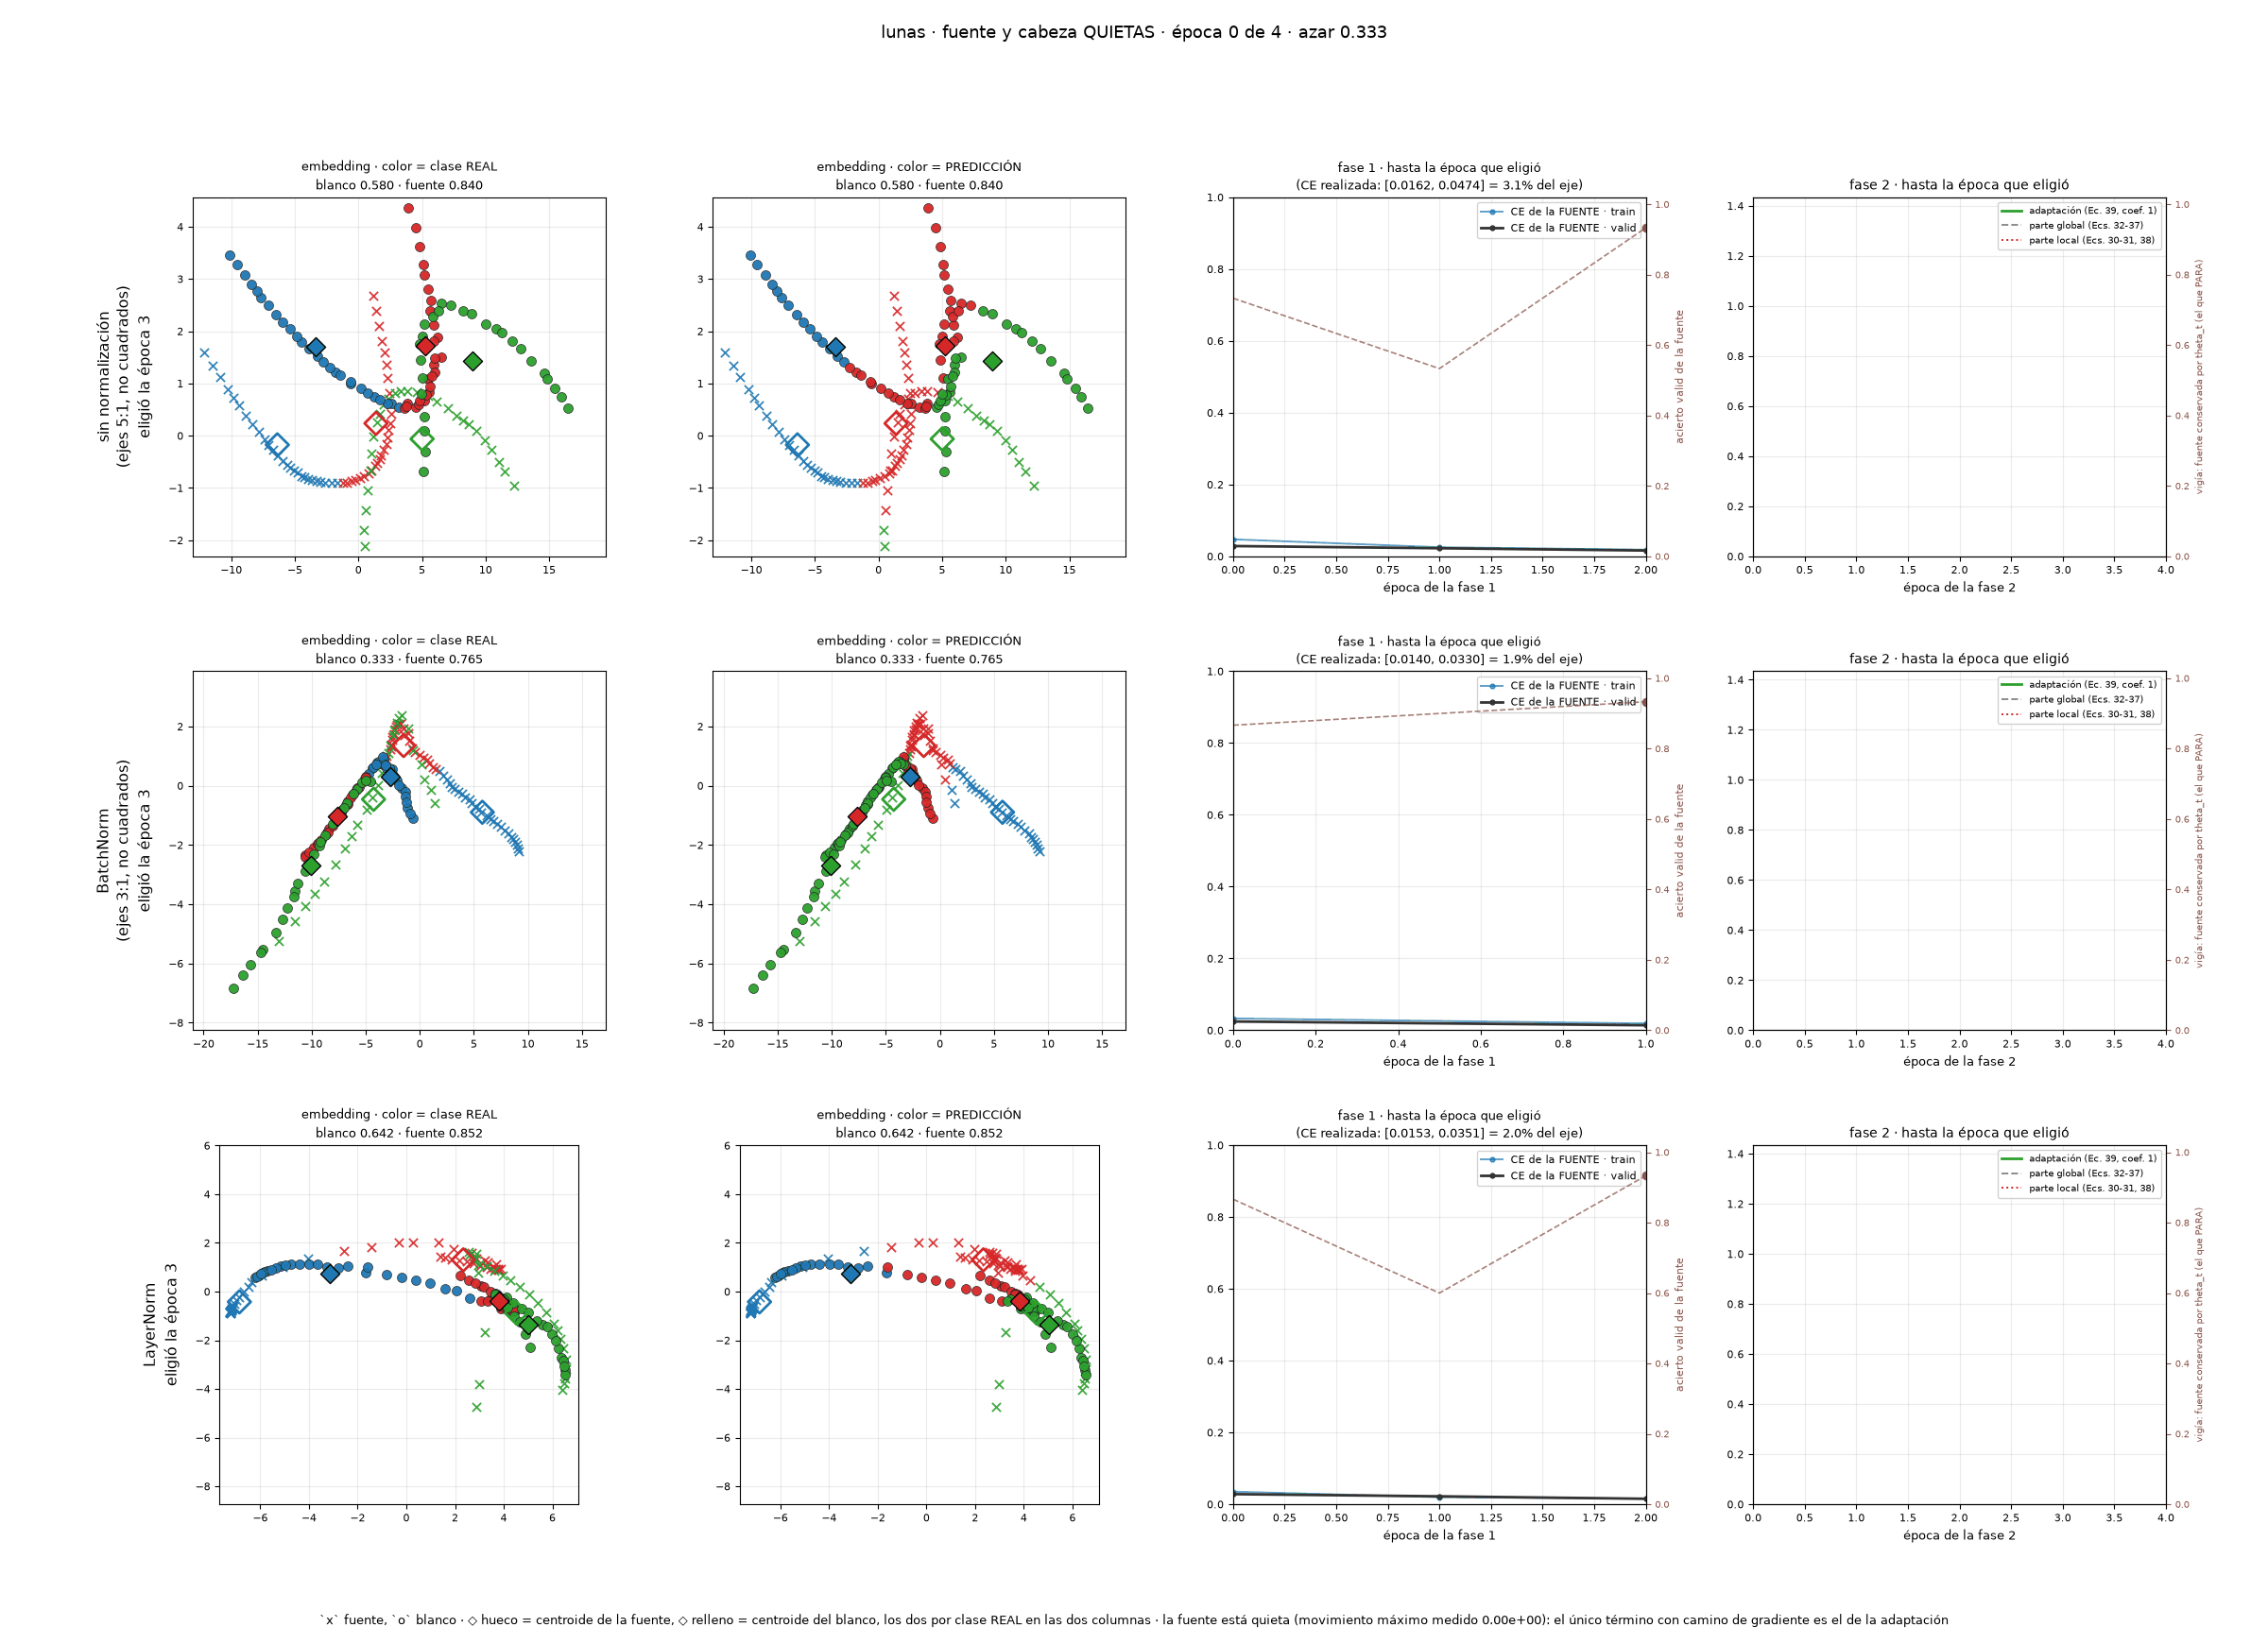

In [6]:
# La imagen y nada mas. El GIF ya se escribio en la celda de `## lunas`, que es
# donde el cuaderno de CREDA lo escribe y donde imprime lo que midio al
# dibujarlo: una celda de figura que ademas imprimiera algo emitiria dos cosas
# donde el documento de al lado emite una.
display(Image(filename=str(ANIMACIONES["lunas"].ruta)))


### lunas — la tabla

**Una tabla, y es la `tabla_dataset` de CREDA para `lunas`**: sus ocho columnas,
en su orden, y sus siete filas. Las filas son los escalones de intervención, de
menos a más —`.predict` una vez por arquitectura, AdaBN donde el backbone guarda
estadísticas corridas que reestimar, y MIL-CREDA una vez por arquitectura—. Qué
mueve cada escalón, cómo se leyó y por qué AdaBN es una sola fila está dicho una
vez arriba, para los tres bloques. La figura de esta familia está justo arriba y
sale del mismo artefacto.

El encabezado de la tabla **lo calcula el registro**: cuántas semillas de reporte
entraron en cada número, qué reducción es, contra qué azar se lee y sobre qué rol
se midió. El hito del azar está además en la tabla de objetivos de arriba, que es
donde dice **por qué** ése es el hito.

Lo que hay que mirar primero es la columna del acierto de la **fuente**: si la
fase 1 no supera el azar en su propio dominio, ningún número del blanco significa
nada —no hay representación que transferir—. Contra qué se lo compara está
dicho una vez arriba: la fase 1 **elige** su mejor época sobre el rol de
selección y el mismo codificador congelado se **lee** sobre el rol que la tabla
publica, que nadie usó para elegir nada. La grilla que dibujaba ese par se
retiró; el número sigue en el artefacto.

La columna del **pico del blanco** trae número en la fila del método y raya en
las que no corrieron una fase 2. La corrida guarda el acierto del blanco en
**cada paso**, sobre el **mismo** rol que publica la columna de al lado, así que
el pico existe y la **brecha entre las dos columnas** es la lectura: dice cuánto
dejó sobre la mesa el paro, y nunca que el blanco se haya usado para elegir
nada. El motivo largo y la raya de los otros dos escalones están arriba, una
vez.

**Y debajo, nada.** Esta celda emite **una** tabla, que es lo que emite la celda
de CREDA. Debajo había una conclusión calculada —las restas, los conteos y los
extremos que la tabla no trae— y se retiró con las otras dos del bloque: el
documento de CREDA no imprime ninguna. Qué lecturas se fueron con ella está
dicho una sola vez, arriba, en la sección de la figura.


In [7]:
display(Markdown(toy_tables.render_familia_escalera(REGISTRO, "lunas")))


**lunas · 1 semilla · media de una sola semilla, sin dispersión · azar 0.3333 · test, sólo reporte**

| método | normalización | época fuente | época que eligió | fuente · test | blanco · test | vigía: fuente conservada | blanco pico · test (oráculo) |
|---|---|---|---|---|---|---|---|
| `.predict` (sin adaptar) | sin normalización | 2 | — | 0.7778 | 0.5556 | — | — |
| `.predict` (sin adaptar) | BatchNorm | 1 | — | 0.6667 | 0.3333 | — | — |
| `.predict` (sin adaptar) | LayerNorm | 2 | — | 0.7778 | 0.6667 | — | — |
| **AdaBN** (sólo buffers, sin optimizador) | BatchNorm | — | — | 0.6667 | 0.5556 | — | — |
| **MIL-CREDA** · HP sintonizados | sin normalización | 2 | 3 | 0.7778 | 0.6111 | 0.8667 | 0.6667 |
| **MIL-CREDA** · HP sintonizados | BatchNorm | 1 | 3 | 0.6667 | 0.7778 | 0.6000 | 0.7778 |
| **MIL-CREDA** · HP sintonizados | LayerNorm | 2 | 3 | 0.7778 | 0.5556 | 0.9333 | 0.6667 |

### lunas — los tests declarados

**Dos tablas, y son las dos de CREDA.** La primera es su `tabla_sin_contra_con`
para `lunas`: el escalón del método contra el escalón cero, **una fila por
arquitectura declarada** y después la fila que promedia, con el t pareado, el
Shapiro sobre las diferencias pareadas y el Wilcoxon al lado. La segunda es su
`tabla_tres_brazos`: los **tres** escalones de la arquitectura donde los tres
existen, una fila por par declarado, con el Friedman arriba de la tabla y la p de
Holm corregida dentro de los pares de esta familia y esa arquitectura.

**El emparejamiento es real y no un supuesto.** Los escalones de una fila salen
de la MISMA celda, así que comparten semilla, material y fase 1 bit a bit
—`.predict` es el punto de control del paso 0 de la corrida cuya fase 2 produce
el acierto del método—, y por eso un par se puede restar. Que la fase 1 no se
movió entre los dos es una **medición** —los pesos y los buffers del codificador
de la fuente, leídos antes y después de la fase 2— y vive en el registro, celda
por celda, para quien lo quiera volver a leer.

**Qué dice cada pie, y qué ya no dice nadie.** El pie de cada tabla lleva el
signo del Δ, contra qué familia corrige Holm, qué eje colapsa `PROMEDIO` y, una
sola vez, por qué las columnas con raya están con raya. Debajo de las dos tablas
había una tercera cosa, una conclusión calculada, y se retiró: el documento de
CREDA emite **dos** tablas acá y nada más. Con ella salieron del documento
cuántos pares produjeron una p, cuántos no tienen segundo escalón que restar,
para cuántas arquitecturas se puede armar la segunda tabla y el extremo de las
diferencias pareadas; los tres primeros se leen contando las rayas de las tablas
que están acá arriba, y el extremo no está.


In [8]:
display(Markdown(toy_tables.render_familia_sin_contra_con(REGISTRO, "lunas")))
display(Markdown(toy_tables.render_familia_tests(REGISTRO, "lunas")))


**lunas · 1 bloque de semilla · test, sólo reporte**

| normalización | MIL-CREDA | `.predict` | Δ = MIL-CREDA − .predict | IC95 de Δ | t(0) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| sin normalización | 0.6111 | 0.5556 | +0.0556 | — | — | — | — | — | 1/1 |
| BatchNorm | 0.7778 | 0.3333 | +0.4444 | — | — | — | — | — | 1/1 |
| LayerNorm | 0.5556 | 0.6667 | -0.1111 | — | — | — | — | — | 0/1 |
| PROMEDIO | 0.6481 | 0.5185 | +0.1296 | — | — | — | — | — | 1/1 |

`Δ = MIL-CREDA − .predict`, así que **Δ>0 quiere decir que gana `MIL-CREDA`** · es el par que CREDA llama `con CREDA` contra `sin CREDA`: `.predict` es esta misma corrida leída en su punto de control del paso 0, así que las dos columnas comparten semilla, material y fase 1 bit a bit. AdaBN no es ninguno de los dos lados —reestima las estadísticas corridas del blanco, que es otra intervención, y sólo existe donde el backbone guarda algo— y sus pares están en la tabla de abajo · `PROMEDIO` promedia la normalización, DENTRO de cada semilla, o sea 1 par, y no agrupa los 3 pares de celda-semilla: la primera semilla de reporte está en las 3 normalizaciones, así que esos pares no son observaciones independientes · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado · las columnas con raya, y por qué: 1 bloque de semilla: con menos de 2 el estadístico de Friedman y la p de Wilcoxon no dependen de los números —son constantes del número de tratamientos y de bloques— así que no se calculan. La diferencia pareada sí es exacta y está en su columna. Hace falta 1 bloque más como mínimo, y la escala completa declara los suyos

**BatchNorm · los 3 escalones**

Sin lectura de Friedman: el pie de la tabla dice con cuántos bloques de semilla cada columna se puede calcular.

| gana si Δ>0 | contra | Δ = 1ª − 2ª | IC95 de Δ | p (Wilcoxon) | p Holm (familia de 0) | gana |
|---|---|---|---|---|---|---|
| AdaBN | `.predict` | +0.2222 | — | — | — | 1/1 |
| MIL-CREDA | `.predict` | +0.4444 | — | — | — | 1/1 |
| MIL-CREDA | AdaBN | +0.2222 | — | — | — | 1/1 |

`Δ = (columna «gana si Δ>0») − (columna «contra»)`, así que **Δ>0 quiere decir que gana el PRIMERO de los dos nombrados** · el orden del par es fijo y no sigue al ganador · Holm dentro de los 0 pares de esta familia y esta arquitectura que produjeron una p, de los 3 declarados, y nunca sobre los 9 de las 3 familias juntas, que es una familia que nadie declaró y corregiría de más · las columnas con raya, y por qué: 1 bloque de semilla: con menos de 2 el estadístico de Friedman y la p de Wilcoxon no dependen de los números —son constantes del número de tratamientos y de bloques— así que no se calculan. La diferencia pareada sí es exacta y está en su columna. Hace falta 1 bloque más como mínimo, y la escala completa declara los suyos

## toroide

In [9]:
# El cuadro animado se escribe ACA, en la celda de la familia, y la celda de la
# figura de abajo solo lo muestra. Es donde el `animar(...)` del cuaderno de
# CREDA imprime, y lo que esta celda emite es lo mismo que la suya: donde quedo
# archivado el GIF, y lo que se midio al dibujarlo. Juntos en la celda de la
# figura eran una imagen con un pie impreso encima --- dos salidas donde el
# documento de al lado tiene una---, y el pie no se puede tirar: sin el, el
# archivo esta en disco y el documento no dice donde.
_anim = toy_run.animar_familia(REGISTRO, "toroide", FIGURAS)
ANIMACIONES["toroide"] = _anim
print("archivado en:", _anim.ruta.relative_to(ROOT))
print("cuadros:", _anim.cuadros, "\u00b7 paso", _anim.paso, "ms")
print("filas, en el orden del registro:",
      [_fila["normalizacion"] for _fila in _anim.filas])
print("filas que CREDA dibuja y este paquete no:",
      ", ".join(_anim.ausentes) or "ninguna")
print("escalones de AdaBN ausentes (el backbone no guarda nada reestimable):",
      ", ".join(_fila["normalizacion"] for _fila in _anim.filas
                if _fila["aciertoAdabn"] is None) or "ninguno")
print("\u00bfuna caja comun para las filas?", _anim.ejes["compartidos"],
      "--- los rangos difieren en un factor de "
      f"{_anim.ejes['discrepanciaRelativa']:.2f} y las bases de PCA forman "
      + ", ".join(f"{_a:.1f} grados"
                  for _a in _anim.ejes["anguloEntreBasesGrados"]))


      toy_paso_toroide.gif  0.80 MB
archivado en: MIL-CREDA/Notebooks/toy_figures/toy_paso_toroide.gif
cuadros: 5 · paso 140 ms
filas, en el orden del registro: ['ninguna', 'batchnorm', 'layernorm']
filas que CREDA dibuja y este paquete no: ninguna
escalones de AdaBN ausentes (el backbone no guarda nada reestimable): ninguna, layernorm
¿una caja comun para las filas? False --- los rangos difieren en un factor de 2.31 y las bases de PCA forman 29.2 grados, 30.0 grados


### toroide — la figura

**El cuadro animado de `toroide`: filas = normalizaciones, cuatro columnas.** Es la
figura por dataset del cuaderno de CREDA, con su misma forma, y sus cuadros son
los pasos de la fase 2. Las columnas uno y dos llevan **las mismas posiciones** y
difieren sólo en el color —clase real contra decisión del cabezal—, así que la
diferencia entre los dos paneles se lee como lo que el cabezal erró y como nada
más. La fila dice en su rótulo, con el nombre que las tablas le dan a la
arquitectura, en qué paso paró; el pie dice cuánto se movió la fuente —que es
cero—.

**Es la única figura de este bloque.** La lámina vectorial estática que estaba
acá arriba se retiró: dibujaba las mismas posiciones sin los pasos, así que era
esta misma medición dibujada dos veces. Los límites y la base de PCA son por
fila y no comunes —cada arquitectura entrena su propio codificador—, y cuánto
difieren los rangos y qué ángulo forman los planos lo imprime **la celda de
arriba**, la de `## toroide`, que es la que dibuja. Medido en vez de afirmado, y en
la celda que lo midió: ésta emite la imagen y nada más, que es lo que emite la
celda de CREDA.


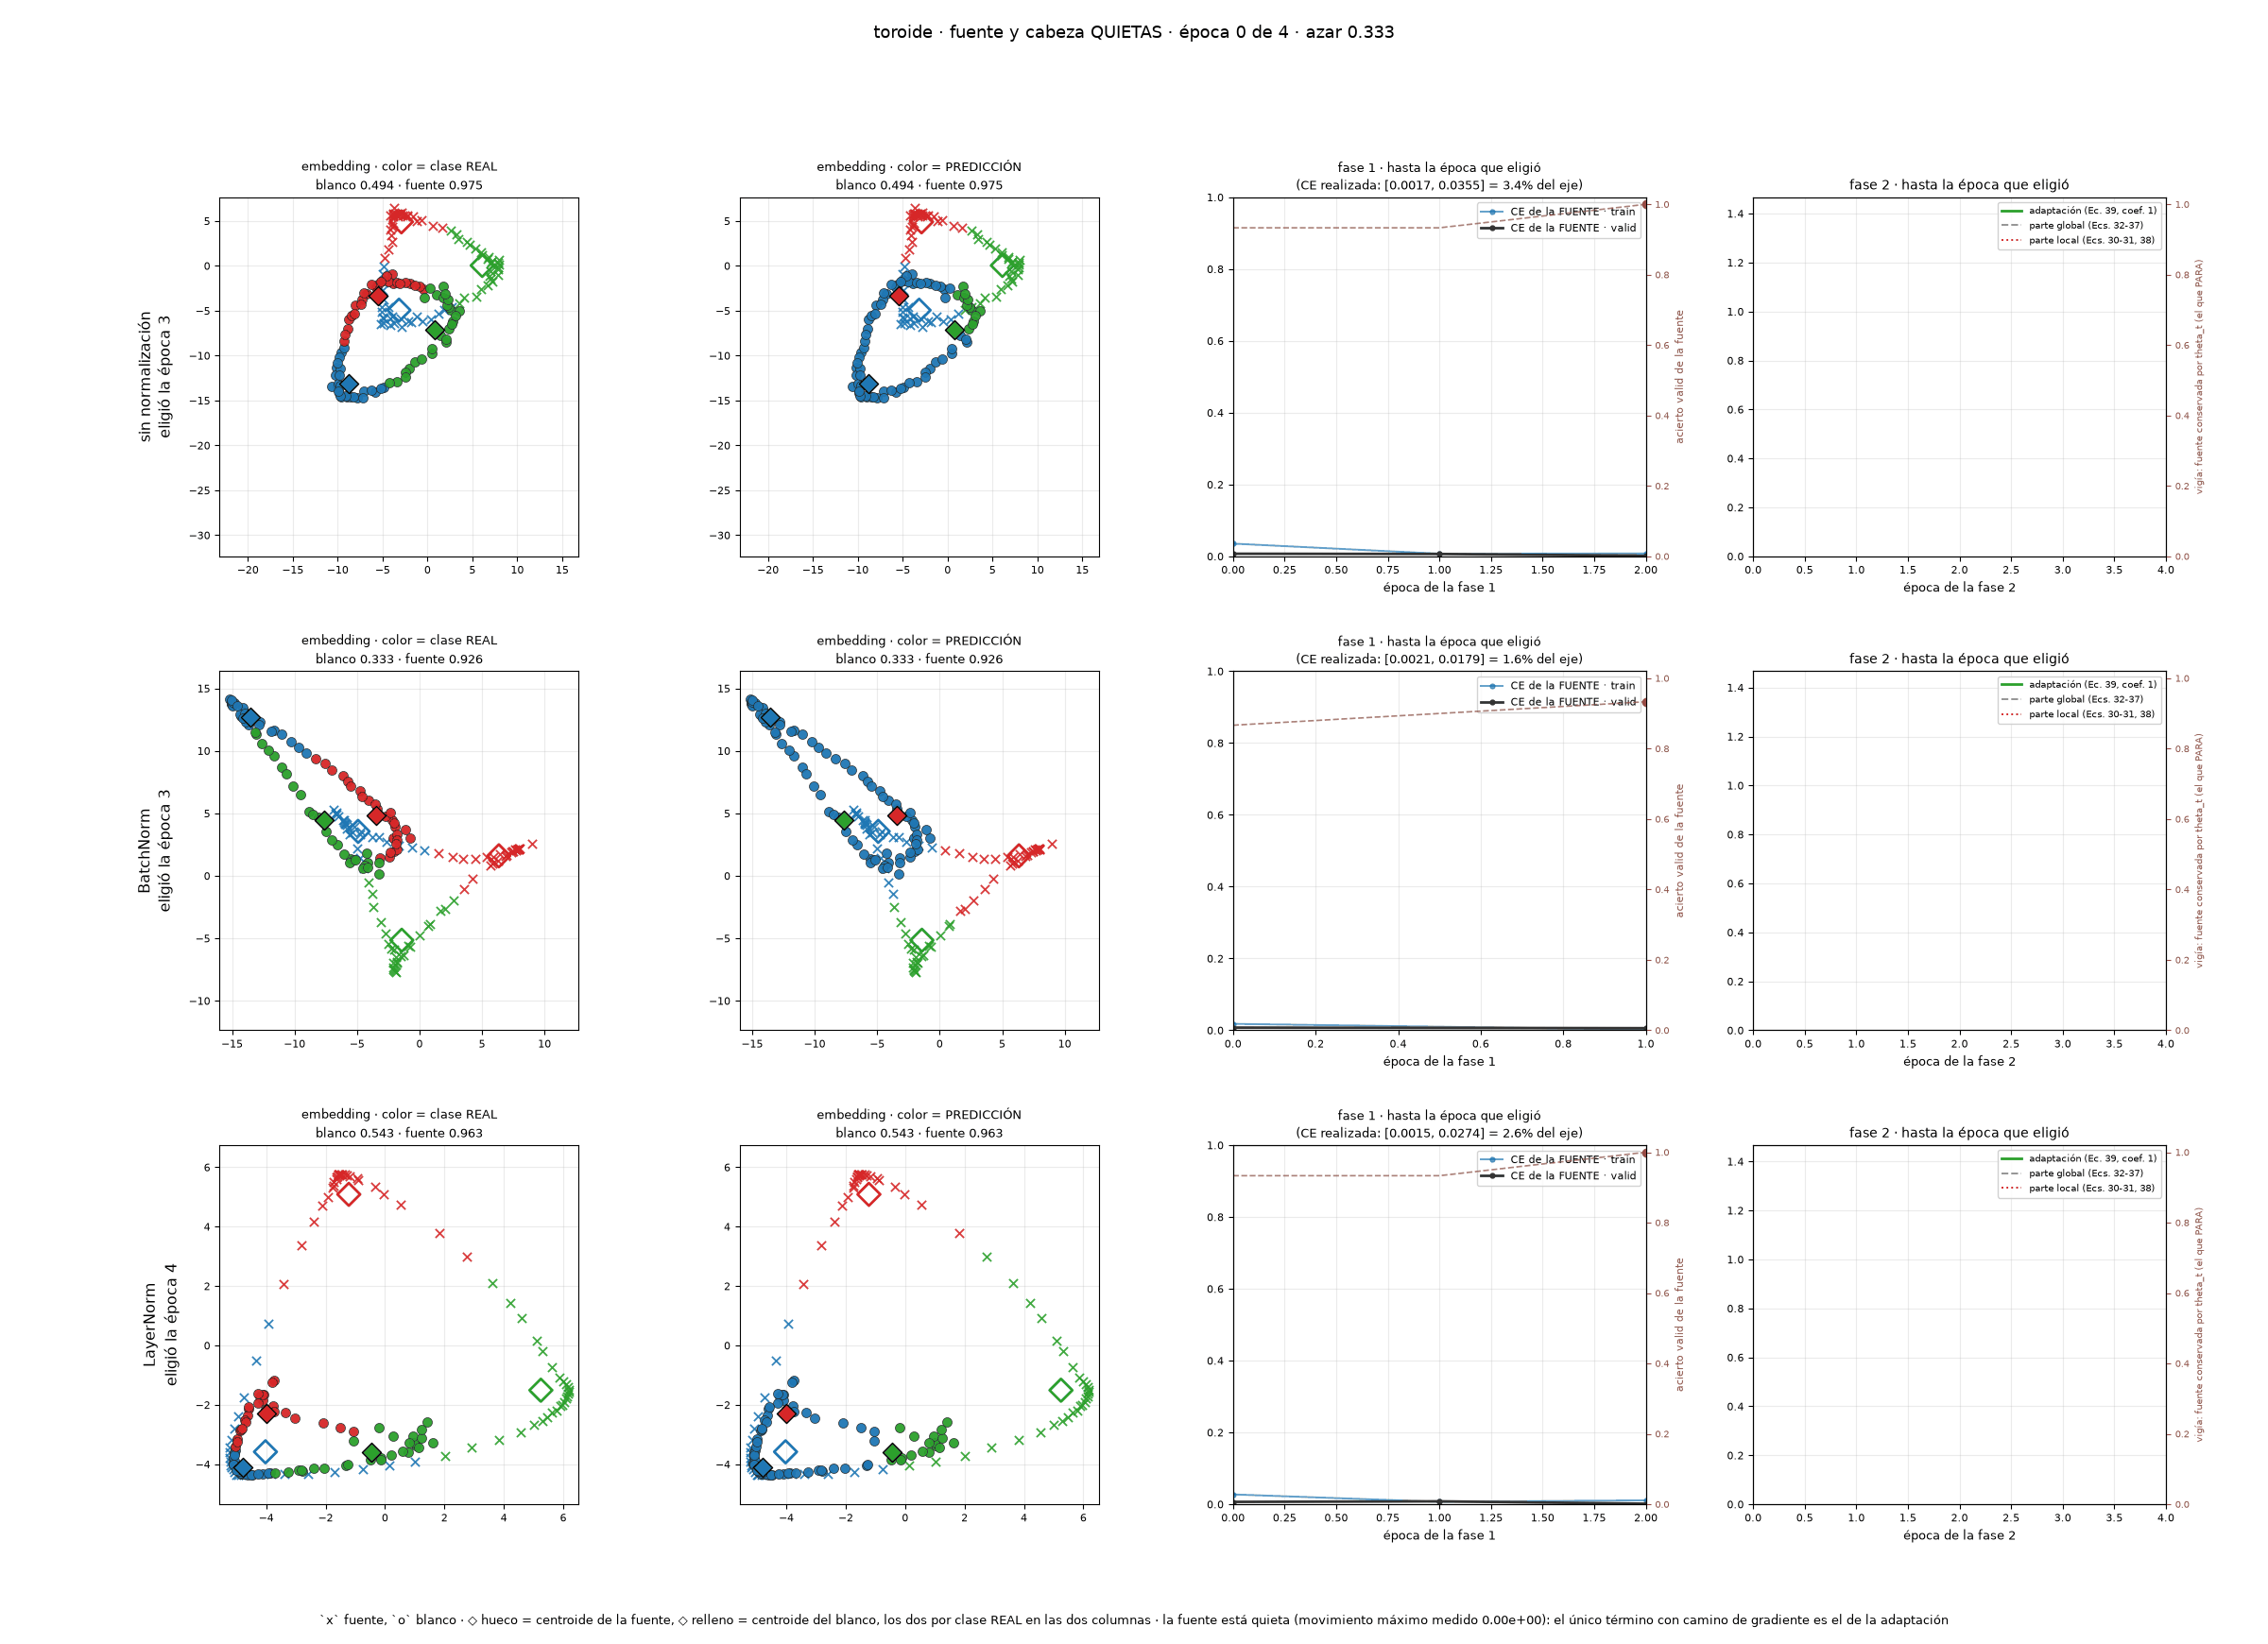

In [10]:
# La imagen y nada mas. El GIF ya se escribio en la celda de `## toroide`, que es
# donde el cuaderno de CREDA lo escribe y donde imprime lo que midio al
# dibujarlo: una celda de figura que ademas imprimiera algo emitiria dos cosas
# donde el documento de al lado emite una.
display(Image(filename=str(ANIMACIONES["toroide"].ruta)))


### toroide — la tabla

**Una tabla, y es la `tabla_dataset` de CREDA para `toroide`**: sus ocho columnas,
en su orden, y sus siete filas. Las filas son los escalones de intervención, de
menos a más —`.predict` una vez por arquitectura, AdaBN donde el backbone guarda
estadísticas corridas que reestimar, y MIL-CREDA una vez por arquitectura—. Qué
mueve cada escalón, cómo se leyó y por qué AdaBN es una sola fila está dicho una
vez arriba, para los tres bloques. La figura de esta familia está justo arriba y
sale del mismo artefacto.

El encabezado de la tabla **lo calcula el registro**: cuántas semillas de reporte
entraron en cada número, qué reducción es, contra qué azar se lee y sobre qué rol
se midió. El hito del azar está además en la tabla de objetivos de arriba, que es
donde dice **por qué** ése es el hito.

Lo que hay que mirar primero es la columna del acierto de la **fuente**: si la
fase 1 no supera el azar en su propio dominio, ningún número del blanco significa
nada —no hay representación que transferir—. Contra qué se lo compara está
dicho una vez arriba: la fase 1 **elige** su mejor época sobre el rol de
selección y el mismo codificador congelado se **lee** sobre el rol que la tabla
publica, que nadie usó para elegir nada. La grilla que dibujaba ese par se
retiró; el número sigue en el artefacto.

La columna del **pico del blanco** trae número en la fila del método y raya en
las que no corrieron una fase 2. La corrida guarda el acierto del blanco en
**cada paso**, sobre el **mismo** rol que publica la columna de al lado, así que
el pico existe y la **brecha entre las dos columnas** es la lectura: dice cuánto
dejó sobre la mesa el paro, y nunca que el blanco se haya usado para elegir
nada. El motivo largo y la raya de los otros dos escalones están arriba, una
vez.

**Y debajo, nada.** Esta celda emite **una** tabla, que es lo que emite la celda
de CREDA. Debajo había una conclusión calculada —las restas, los conteos y los
extremos que la tabla no trae— y se retiró con las otras dos del bloque: el
documento de CREDA no imprime ninguna. Qué lecturas se fueron con ella está
dicho una sola vez, arriba, en la sección de la figura.


In [11]:
display(Markdown(toy_tables.render_familia_escalera(REGISTRO, "toroide")))


**toroide · 1 semilla · media de una sola semilla, sin dispersión · azar 0.3333 · test, sólo reporte**

| método | normalización | época fuente | época que eligió | fuente · test | blanco · test | vigía: fuente conservada | blanco pico · test (oráculo) |
|---|---|---|---|---|---|---|---|
| `.predict` (sin adaptar) | sin normalización | 2 | — | 1.0000 | 0.5556 | — | — |
| `.predict` (sin adaptar) | BatchNorm | 1 | — | 0.9444 | 0.3333 | — | — |
| `.predict` (sin adaptar) | LayerNorm | 2 | — | 1.0000 | 0.5556 | — | — |
| **AdaBN** (sólo buffers, sin optimizador) | BatchNorm | — | — | 0.9444 | 1.0000 | — | — |
| **MIL-CREDA** · HP sintonizados | sin normalización | 2 | 3 | 1.0000 | 0.6111 | 1.0000 | 0.6111 |
| **MIL-CREDA** · HP sintonizados | BatchNorm | 1 | 3 | 0.9444 | 0.9444 | 0.6667 | 1.0000 |
| **MIL-CREDA** · HP sintonizados | LayerNorm | 2 | 4 | 1.0000 | 0.8333 | 0.9333 | 0.9444 |

### toroide — los tests declarados

**Dos tablas, y son las dos de CREDA.** La primera es su `tabla_sin_contra_con`
para `toroide`: el escalón del método contra el escalón cero, **una fila por
arquitectura declarada** y después la fila que promedia, con el t pareado, el
Shapiro sobre las diferencias pareadas y el Wilcoxon al lado. La segunda es su
`tabla_tres_brazos`: los **tres** escalones de la arquitectura donde los tres
existen, una fila por par declarado, con el Friedman arriba de la tabla y la p de
Holm corregida dentro de los pares de esta familia y esa arquitectura.

**El emparejamiento es real y no un supuesto.** Los escalones de una fila salen
de la MISMA celda, así que comparten semilla, material y fase 1 bit a bit
—`.predict` es el punto de control del paso 0 de la corrida cuya fase 2 produce
el acierto del método—, y por eso un par se puede restar. Que la fase 1 no se
movió entre los dos es una **medición** —los pesos y los buffers del codificador
de la fuente, leídos antes y después de la fase 2— y vive en el registro, celda
por celda, para quien lo quiera volver a leer.

**Qué dice cada pie, y qué ya no dice nadie.** El pie de cada tabla lleva el
signo del Δ, contra qué familia corrige Holm, qué eje colapsa `PROMEDIO` y, una
sola vez, por qué las columnas con raya están con raya. Debajo de las dos tablas
había una tercera cosa, una conclusión calculada, y se retiró: el documento de
CREDA emite **dos** tablas acá y nada más. Con ella salieron del documento
cuántos pares produjeron una p, cuántos no tienen segundo escalón que restar,
para cuántas arquitecturas se puede armar la segunda tabla y el extremo de las
diferencias pareadas; los tres primeros se leen contando las rayas de las tablas
que están acá arriba, y el extremo no está.


In [12]:
display(Markdown(toy_tables.render_familia_sin_contra_con(REGISTRO, "toroide")))
display(Markdown(toy_tables.render_familia_tests(REGISTRO, "toroide")))


**toroide · 1 bloque de semilla · test, sólo reporte**

| normalización | MIL-CREDA | `.predict` | Δ = MIL-CREDA − .predict | IC95 de Δ | t(0) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| sin normalización | 0.6111 | 0.5556 | +0.0556 | — | — | — | — | — | 1/1 |
| BatchNorm | 0.9444 | 0.3333 | +0.6111 | — | — | — | — | — | 1/1 |
| LayerNorm | 0.8333 | 0.5556 | +0.2778 | — | — | — | — | — | 1/1 |
| PROMEDIO | 0.7963 | 0.4815 | +0.3148 | — | — | — | — | — | 1/1 |

`Δ = MIL-CREDA − .predict`, así que **Δ>0 quiere decir que gana `MIL-CREDA`** · es el par que CREDA llama `con CREDA` contra `sin CREDA`: `.predict` es esta misma corrida leída en su punto de control del paso 0, así que las dos columnas comparten semilla, material y fase 1 bit a bit. AdaBN no es ninguno de los dos lados —reestima las estadísticas corridas del blanco, que es otra intervención, y sólo existe donde el backbone guarda algo— y sus pares están en la tabla de abajo · `PROMEDIO` promedia la normalización, DENTRO de cada semilla, o sea 1 par, y no agrupa los 3 pares de celda-semilla: la primera semilla de reporte está en las 3 normalizaciones, así que esos pares no son observaciones independientes · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado · las columnas con raya, y por qué: 1 bloque de semilla: con menos de 2 el estadístico de Friedman y la p de Wilcoxon no dependen de los números —son constantes del número de tratamientos y de bloques— así que no se calculan. La diferencia pareada sí es exacta y está en su columna. Hace falta 1 bloque más como mínimo, y la escala completa declara los suyos

**BatchNorm · los 3 escalones**

Sin lectura de Friedman: el pie de la tabla dice con cuántos bloques de semilla cada columna se puede calcular.

| gana si Δ>0 | contra | Δ = 1ª − 2ª | IC95 de Δ | p (Wilcoxon) | p Holm (familia de 0) | gana |
|---|---|---|---|---|---|---|
| AdaBN | `.predict` | +0.6667 | — | — | — | 1/1 |
| MIL-CREDA | `.predict` | +0.6111 | — | — | — | 1/1 |
| MIL-CREDA | AdaBN | -0.0556 | — | — | — | 0/1 |

`Δ = (columna «gana si Δ>0») − (columna «contra»)`, así que **Δ>0 quiere decir que gana el PRIMERO de los dos nombrados** · el orden del par es fijo y no sigue al ganador · Holm dentro de los 0 pares de esta familia y esta arquitectura que produjeron una p, de los 3 declarados, y nunca sobre los 9 de las 3 familias juntas, que es una familia que nadie declaró y corregiría de más · las columnas con raya, y por qué: 1 bloque de semilla: con menos de 2 el estadístico de Friedman y la p de Wilcoxon no dependen de los números —son constantes del número de tratamientos y de bloques— así que no se calculan. La diferencia pareada sí es exacta y está en su columna. Hace falta 1 bloque más como mínimo, y la escala completa declara los suyos

## rollo

In [13]:
# El cuadro animado se escribe ACA, en la celda de la familia, y la celda de la
# figura de abajo solo lo muestra. Es donde el `animar(...)` del cuaderno de
# CREDA imprime, y lo que esta celda emite es lo mismo que la suya: donde quedo
# archivado el GIF, y lo que se midio al dibujarlo. Juntos en la celda de la
# figura eran una imagen con un pie impreso encima --- dos salidas donde el
# documento de al lado tiene una---, y el pie no se puede tirar: sin el, el
# archivo esta en disco y el documento no dice donde.
_anim = toy_run.animar_familia(REGISTRO, "rollo", FIGURAS)
ANIMACIONES["rollo"] = _anim
print("archivado en:", _anim.ruta.relative_to(ROOT))
print("cuadros:", _anim.cuadros, "\u00b7 paso", _anim.paso, "ms")
print("filas, en el orden del registro:",
      [_fila["normalizacion"] for _fila in _anim.filas])
print("filas que CREDA dibuja y este paquete no:",
      ", ".join(_anim.ausentes) or "ninguna")
print("escalones de AdaBN ausentes (el backbone no guarda nada reestimable):",
      ", ".join(_fila["normalizacion"] for _fila in _anim.filas
                if _fila["aciertoAdabn"] is None) or "ninguno")
print("\u00bfuna caja comun para las filas?", _anim.ejes["compartidos"],
      "--- los rangos difieren en un factor de "
      f"{_anim.ejes['discrepanciaRelativa']:.2f} y las bases de PCA forman "
      + ", ".join(f"{_a:.1f} grados"
                  for _a in _anim.ejes["anguloEntreBasesGrados"]))


      toy_paso_rollo.gif  1.17 MB
archivado en: MIL-CREDA/Notebooks/toy_figures/toy_paso_rollo.gif
cuadros: 5 · paso 140 ms
filas, en el orden del registro: ['ninguna', 'batchnorm', 'layernorm']
filas que CREDA dibuja y este paquete no: ninguna
escalones de AdaBN ausentes (el backbone no guarda nada reestimable): ninguna, layernorm
¿una caja comun para las filas? False --- los rangos difieren en un factor de 9.02 y las bases de PCA forman 35.9 grados, 44.1 grados


### rollo — la figura

**El cuadro animado de `rollo`: filas = normalizaciones, cuatro columnas.** Es la
figura por dataset del cuaderno de CREDA, con su misma forma, y sus cuadros son
los pasos de la fase 2. Las columnas uno y dos llevan **las mismas posiciones** y
difieren sólo en el color —clase real contra decisión del cabezal—, así que la
diferencia entre los dos paneles se lee como lo que el cabezal erró y como nada
más. La fila dice en su rótulo, con el nombre que las tablas le dan a la
arquitectura, en qué paso paró; el pie dice cuánto se movió la fuente —que es
cero—.

**Es la única figura de este bloque.** La lámina vectorial estática que estaba
acá arriba se retiró: dibujaba las mismas posiciones sin los pasos, así que era
esta misma medición dibujada dos veces. Los límites y la base de PCA son por
fila y no comunes —cada arquitectura entrena su propio codificador—, y cuánto
difieren los rangos y qué ángulo forman los planos lo imprime **la celda de
arriba**, la de `## rollo`, que es la que dibuja. Medido en vez de afirmado, y en
la celda que lo midió: ésta emite la imagen y nada más, que es lo que emite la
celda de CREDA.


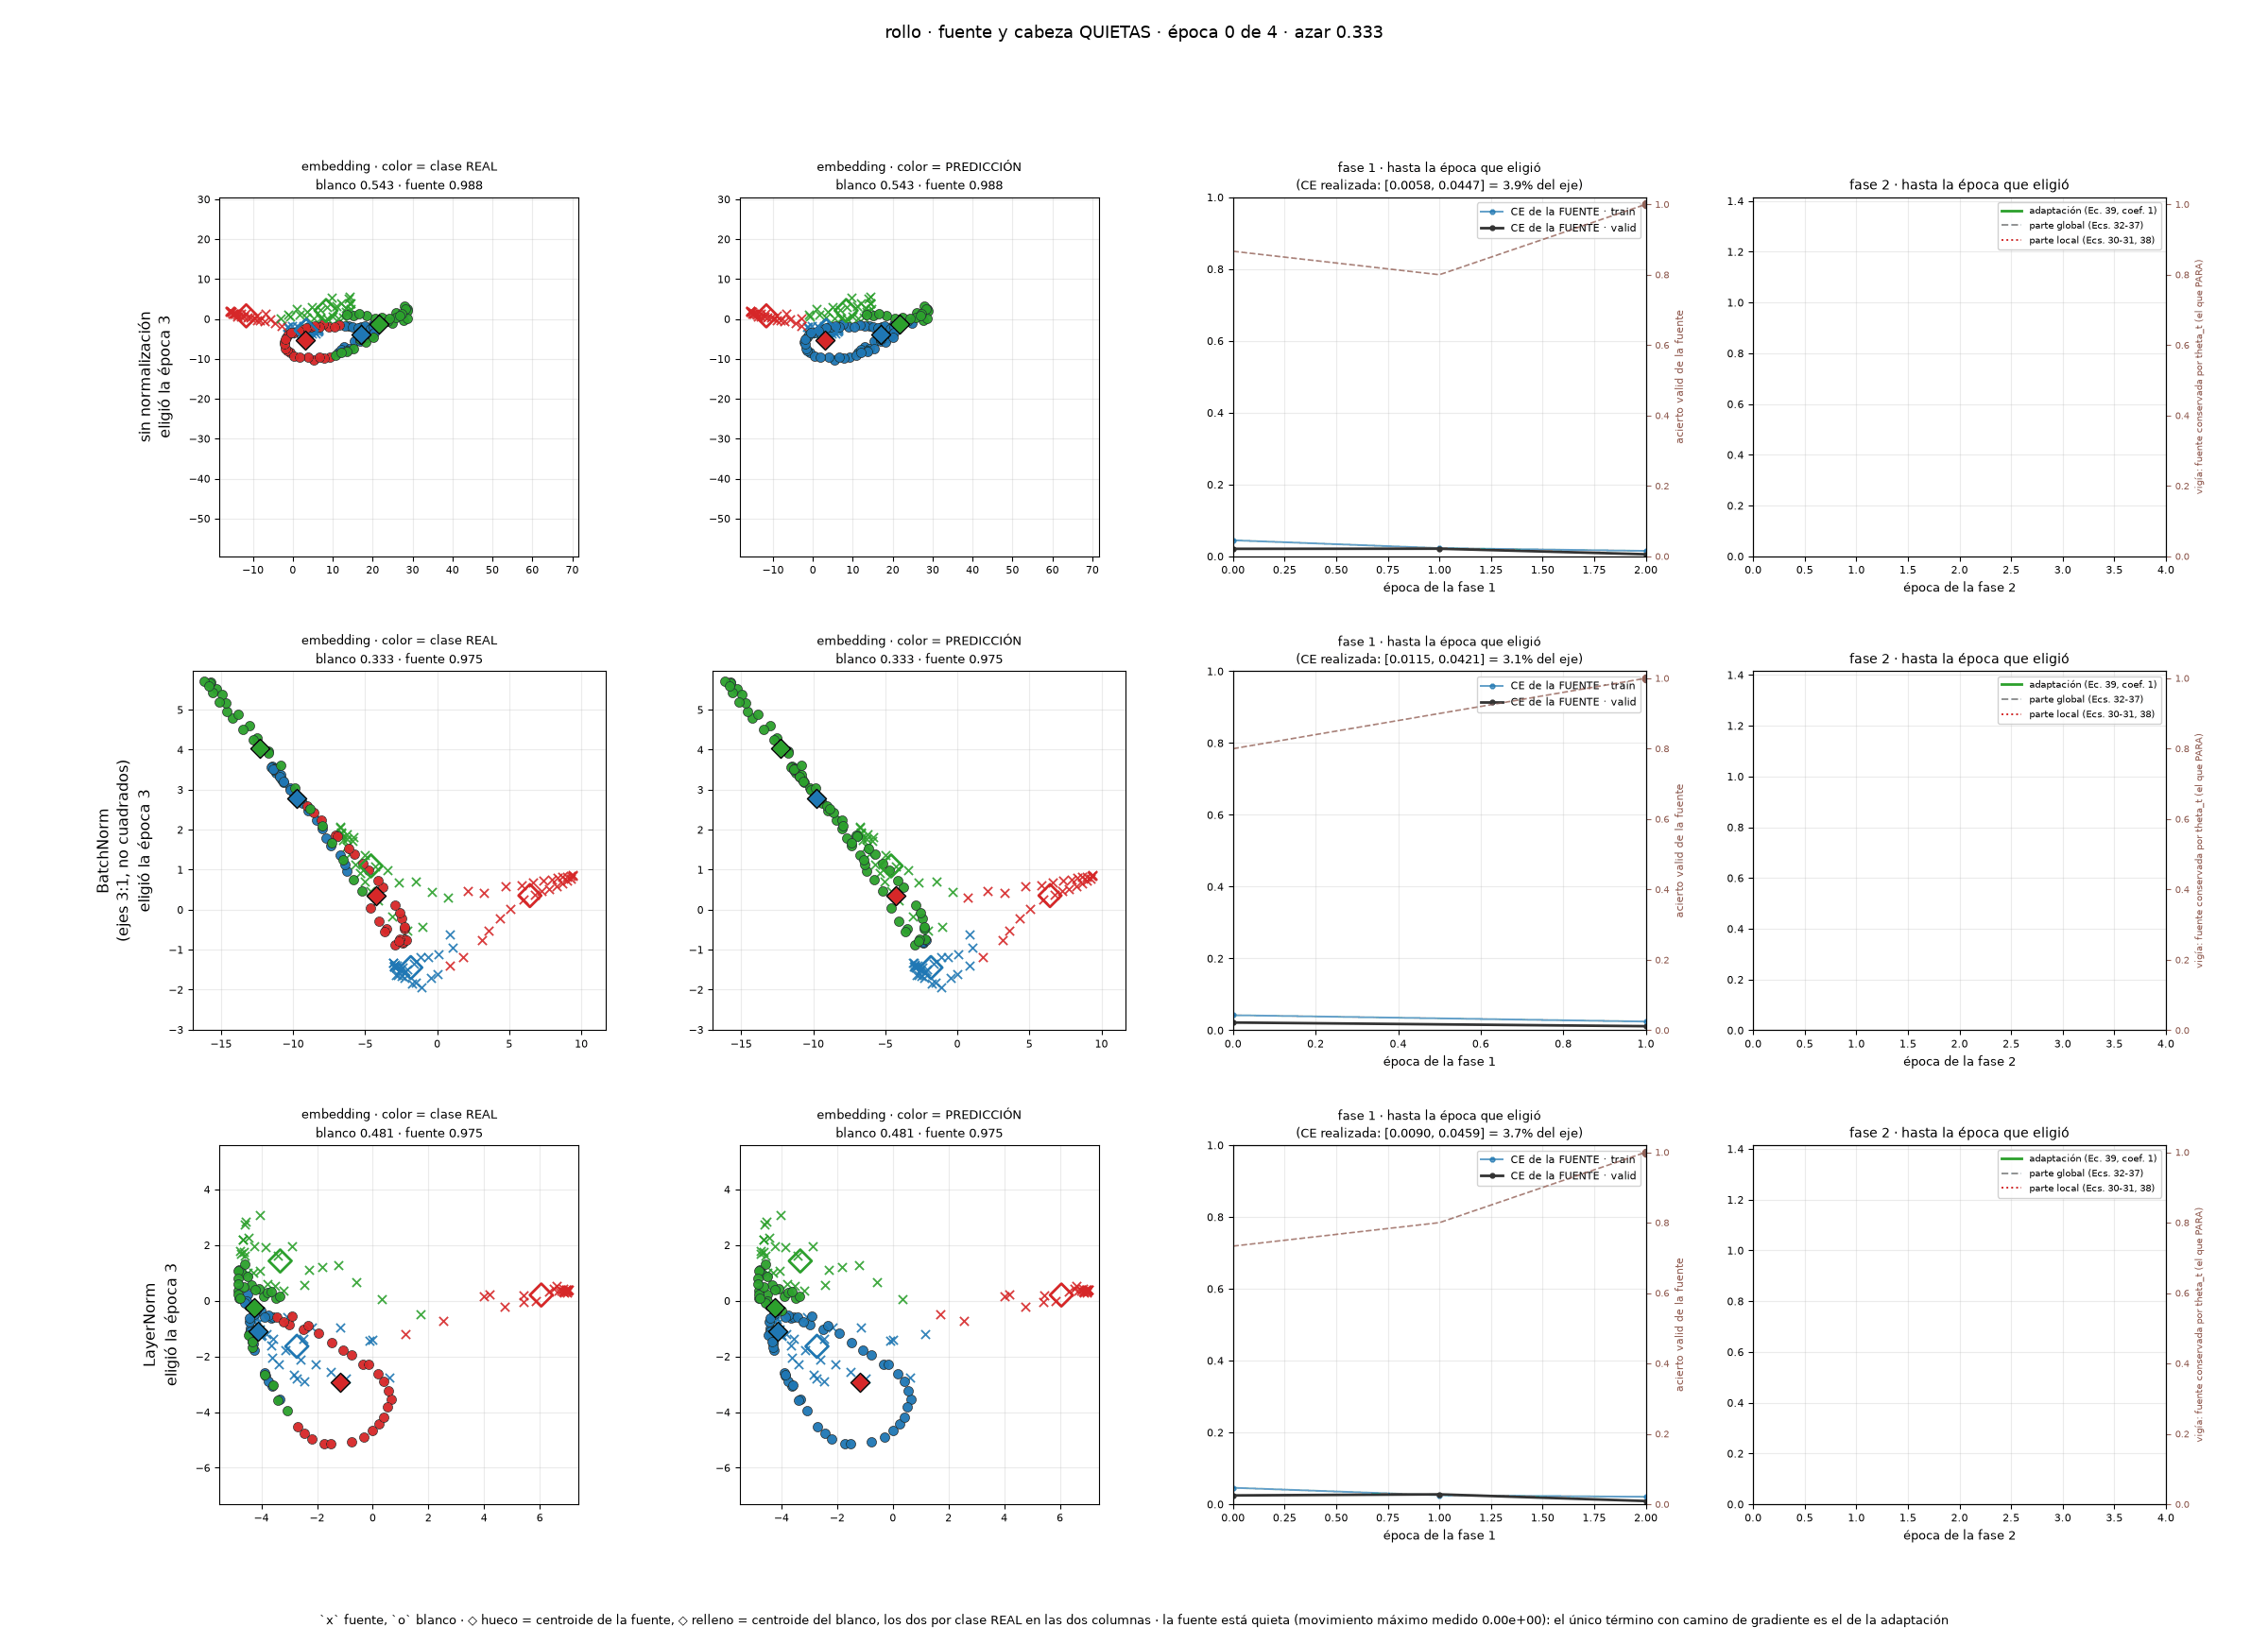

In [14]:
# La imagen y nada mas. El GIF ya se escribio en la celda de `## rollo`, que es
# donde el cuaderno de CREDA lo escribe y donde imprime lo que midio al
# dibujarlo: una celda de figura que ademas imprimiera algo emitiria dos cosas
# donde el documento de al lado emite una.
display(Image(filename=str(ANIMACIONES["rollo"].ruta)))


### rollo — la tabla

**Una tabla, y es la `tabla_dataset` de CREDA para `rollo`**: sus ocho columnas,
en su orden, y sus siete filas. Las filas son los escalones de intervención, de
menos a más —`.predict` una vez por arquitectura, AdaBN donde el backbone guarda
estadísticas corridas que reestimar, y MIL-CREDA una vez por arquitectura—. Qué
mueve cada escalón, cómo se leyó y por qué AdaBN es una sola fila está dicho una
vez arriba, para los tres bloques. La figura de esta familia está justo arriba y
sale del mismo artefacto.

El encabezado de la tabla **lo calcula el registro**: cuántas semillas de reporte
entraron en cada número, qué reducción es, contra qué azar se lee y sobre qué rol
se midió. El hito del azar está además en la tabla de objetivos de arriba, que es
donde dice **por qué** ése es el hito.

Lo que hay que mirar primero es la columna del acierto de la **fuente**: si la
fase 1 no supera el azar en su propio dominio, ningún número del blanco significa
nada —no hay representación que transferir—. Contra qué se lo compara está
dicho una vez arriba: la fase 1 **elige** su mejor época sobre el rol de
selección y el mismo codificador congelado se **lee** sobre el rol que la tabla
publica, que nadie usó para elegir nada. La grilla que dibujaba ese par se
retiró; el número sigue en el artefacto.

La columna del **pico del blanco** trae número en la fila del método y raya en
las que no corrieron una fase 2. La corrida guarda el acierto del blanco en
**cada paso**, sobre el **mismo** rol que publica la columna de al lado, así que
el pico existe y la **brecha entre las dos columnas** es la lectura: dice cuánto
dejó sobre la mesa el paro, y nunca que el blanco se haya usado para elegir
nada. El motivo largo y la raya de los otros dos escalones están arriba, una
vez.

**Y debajo, nada.** Esta celda emite **una** tabla, que es lo que emite la celda
de CREDA. Debajo había una conclusión calculada —las restas, los conteos y los
extremos que la tabla no trae— y se retiró con las otras dos del bloque: el
documento de CREDA no imprime ninguna. Qué lecturas se fueron con ella está
dicho una sola vez, arriba, en la sección de la figura.


In [15]:
display(Markdown(toy_tables.render_familia_escalera(REGISTRO, "rollo")))


**rollo · 1 semilla · media de una sola semilla, sin dispersión · azar 0.3333 · test, sólo reporte**

| método | normalización | época fuente | época que eligió | fuente · test | blanco · test | vigía: fuente conservada | blanco pico · test (oráculo) |
|---|---|---|---|---|---|---|---|
| `.predict` (sin adaptar) | sin normalización | 2 | — | 1.0000 | 0.4444 | — | — |
| `.predict` (sin adaptar) | BatchNorm | 1 | — | 1.0000 | 0.3333 | — | — |
| `.predict` (sin adaptar) | LayerNorm | 2 | — | 1.0000 | 0.5000 | — | — |
| **AdaBN** (sólo buffers, sin optimizador) | BatchNorm | — | — | 1.0000 | 0.7778 | — | — |
| **MIL-CREDA** · HP sintonizados | sin normalización | 2 | 3 | 1.0000 | 0.3333 | 0.5333 | 0.4444 |
| **MIL-CREDA** · HP sintonizados | BatchNorm | 1 | 3 | 1.0000 | 0.9444 | 0.6000 | 1.0000 |
| **MIL-CREDA** · HP sintonizados | LayerNorm | 2 | 3 | 1.0000 | 0.3333 | 0.8000 | 0.5000 |

### rollo — los tests declarados

**Dos tablas, y son las dos de CREDA.** La primera es su `tabla_sin_contra_con`
para `rollo`: el escalón del método contra el escalón cero, **una fila por
arquitectura declarada** y después la fila que promedia, con el t pareado, el
Shapiro sobre las diferencias pareadas y el Wilcoxon al lado. La segunda es su
`tabla_tres_brazos`: los **tres** escalones de la arquitectura donde los tres
existen, una fila por par declarado, con el Friedman arriba de la tabla y la p de
Holm corregida dentro de los pares de esta familia y esa arquitectura.

**El emparejamiento es real y no un supuesto.** Los escalones de una fila salen
de la MISMA celda, así que comparten semilla, material y fase 1 bit a bit
—`.predict` es el punto de control del paso 0 de la corrida cuya fase 2 produce
el acierto del método—, y por eso un par se puede restar. Que la fase 1 no se
movió entre los dos es una **medición** —los pesos y los buffers del codificador
de la fuente, leídos antes y después de la fase 2— y vive en el registro, celda
por celda, para quien lo quiera volver a leer.

**Qué dice cada pie, y qué ya no dice nadie.** El pie de cada tabla lleva el
signo del Δ, contra qué familia corrige Holm, qué eje colapsa `PROMEDIO` y, una
sola vez, por qué las columnas con raya están con raya. Debajo de las dos tablas
había una tercera cosa, una conclusión calculada, y se retiró: el documento de
CREDA emite **dos** tablas acá y nada más. Con ella salieron del documento
cuántos pares produjeron una p, cuántos no tienen segundo escalón que restar,
para cuántas arquitecturas se puede armar la segunda tabla y el extremo de las
diferencias pareadas; los tres primeros se leen contando las rayas de las tablas
que están acá arriba, y el extremo no está.


In [16]:
display(Markdown(toy_tables.render_familia_sin_contra_con(REGISTRO, "rollo")))
display(Markdown(toy_tables.render_familia_tests(REGISTRO, "rollo")))


**rollo · 1 bloque de semilla · test, sólo reporte**

| normalización | MIL-CREDA | `.predict` | Δ = MIL-CREDA − .predict | IC95 de Δ | t(0) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| sin normalización | 0.3333 | 0.4444 | -0.1111 | — | — | — | — | — | 0/1 |
| BatchNorm | 0.9444 | 0.3333 | +0.6111 | — | — | — | — | — | 1/1 |
| LayerNorm | 0.3333 | 0.5000 | -0.1667 | — | — | — | — | — | 0/1 |
| PROMEDIO | 0.5370 | 0.4259 | +0.1111 | — | — | — | — | — | 1/1 |

`Δ = MIL-CREDA − .predict`, así que **Δ>0 quiere decir que gana `MIL-CREDA`** · es el par que CREDA llama `con CREDA` contra `sin CREDA`: `.predict` es esta misma corrida leída en su punto de control del paso 0, así que las dos columnas comparten semilla, material y fase 1 bit a bit. AdaBN no es ninguno de los dos lados —reestima las estadísticas corridas del blanco, que es otra intervención, y sólo existe donde el backbone guarda algo— y sus pares están en la tabla de abajo · `PROMEDIO` promedia la normalización, DENTRO de cada semilla, o sea 1 par, y no agrupa los 3 pares de celda-semilla: la primera semilla de reporte está en las 3 normalizaciones, así que esos pares no son observaciones independientes · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado · las columnas con raya, y por qué: 1 bloque de semilla: con menos de 2 el estadístico de Friedman y la p de Wilcoxon no dependen de los números —son constantes del número de tratamientos y de bloques— así que no se calculan. La diferencia pareada sí es exacta y está en su columna. Hace falta 1 bloque más como mínimo, y la escala completa declara los suyos

**BatchNorm · los 3 escalones**

Sin lectura de Friedman: el pie de la tabla dice con cuántos bloques de semilla cada columna se puede calcular.

| gana si Δ>0 | contra | Δ = 1ª − 2ª | IC95 de Δ | p (Wilcoxon) | p Holm (familia de 0) | gana |
|---|---|---|---|---|---|---|
| AdaBN | `.predict` | +0.4444 | — | — | — | 1/1 |
| MIL-CREDA | `.predict` | +0.6111 | — | — | — | 1/1 |
| MIL-CREDA | AdaBN | +0.1667 | — | — | — | 1/1 |

`Δ = (columna «gana si Δ>0») − (columna «contra»)`, así que **Δ>0 quiere decir que gana el PRIMERO de los dos nombrados** · el orden del par es fijo y no sigue al ganador · Holm dentro de los 0 pares de esta familia y esta arquitectura que produjeron una p, de los 3 declarados, y nunca sobre los 9 de las 3 familias juntas, que es una familia que nadie declaró y corregiría de más · las columnas con raya, y por qué: 1 bloque de semilla: con menos de 2 el estadístico de Friedman y la p de Wilcoxon no dependen de los números —son constantes del número de tratamientos y de bloques— así que no se calculan. La diferencia pareada sí es exacta y está en su columna. Hace falta 1 bloque más como mínimo, y la escala completa declara los suyos

## El sopesado, por construcción

Acá va lo que en el cuaderno de CREDA es la última sección: qué le hace el peso
de la confianza a un punto que se mueve de una frontera de decisión del cabezal
al centro de una clase. **Hoy está vacía, y vacía es lo honesto.**

Lo que le falta es un cabezal entrenado sobre estas bolsas. El peso no es una
medición con varianza —es una función del posterior, exacta— pero un posterior
necesita un modelo, y para este toyset no hay ninguno. Para entrenarlo hay que
correr antes la búsqueda bajo la revisión que el paquete declara, y el único
registro de techos que hay en disco,
`MIL-CREDA/Results/Benchmark/ceilings.pilot.json`, quedó sellado bajo una
revisión anterior a la que `config.REVISION` declara.
`ceiling_record.stamp_drift` reporta exactamente esa diferencia, y
`harness.ceilings_in_force` se niega a usar el registro por ella: corta con un
`SystemExit` que dice que los techos están sellados bajo otra revisión o bajo
otros hiperparámetros. Es un registro de **ensayo**, además, así que tampoco hay
una búsqueda a escala completa que haya elegido nada.

Así que el orden es: correr la búsqueda bajo la revisión declarada, entrenar un
cabezal sobre estas bolsas, y entonces esta sección se llena con la misma figura
que tiene el cuaderno de CREDA.

Lo que **no** se hace acá: no se inventa ningún número, no se entrena nada de
apuro, y no se pone otra figura en este lugar diciendo que es el sopesado. Una
sección vacía y declarada se llena cuando corresponde; una llena con algo que
mide otra cosa se cita, y después se cita la cita.

In [17]:
# El sello: contra qué código corrió este cuaderno. Sin él, una corrida vieja y
# una recién hecha se ven idénticas y la vieja se sigue creyendo. Cubre todo
# `src/`, así que un cambio en cualquier módulo lo mueve --- es más grueso que lo
# que este cuaderno lee, y eso es deliberado: una regla más fina es una regla que
# dos implementaciones del sello pueden entender distinto.
from MIL_CREDA_Benchmark import report_digest

print(report_digest.stamp())

SOURCES-SHA256 92c9901a75d5f0e6436c897353b9f021368c96a27c115ac3b234fb0ec5bc3d4a
